# Objective

- Predict the probability that an applicant has payment difficulties (`TARGET = 1`) on a Home Credit loan.

# Reason

- Decide who to lend to, and on what terms.
- Expected-loss estimates for pricing and provisioning.
- Calibrated probabilities, not just a ranking: the loss estimate is only as good as the probability behind it.

# Naive Hypotheses

| # | Hypothesis | Mechanism | Expected direction | Columns used | EDA test |
|---|---|---|---|---|---|
| H1 | Affordability net of risk | The `EXT_SOURCE_*` scores are external risk scores, so raw affordability partly duplicates them. A heavy repayment burden *for a given score* should still add risk. | Raw burden: weak. Burden within a score band: ↑ default | `AMT_ANNUITY`, `AMT_INCOME_TOTAL`, `EXT_SOURCE_2` | Default rate by annuity-to-income decile × `EXT_SOURCE_2` decile |
| H2 | Credit seeking vs paying down | Opening many credits recently suggests cash-flow stress; paying credits off early suggests spare cash. | ↑ default with credits opened and enquiries; ↓ with early payoffs | `bureau.csv` dates, `AMT_REQ_CREDIT_BUREAU_*` | Default rate by credits opened in the last 12 months, and by early payoffs |
| H3 | Homeowners and pensioners | Property is a wealth buffer, and pensions are stable income. But a pensioner who needs to borrow may have little liquidity. | Owners ↓; pensioners ↓, weaker among non-owners | `FLAG_OWN_REALTY`, `NAME_INCOME_TYPE` | Default-rate grid of `NAME_INCOME_TYPE` × `FLAG_OWN_REALTY`, with cell counts |
| H4 | Term / exposure | ↑ time implies ↑ variance: more time for circumstances to change | ↑ with term | `AMT_CREDIT / AMT_ANNUITY` (implied term, cash loans only) | Default rate by term quintile × `EXT_SOURCE_2` decile |
| H5 | Home Credit's own judgement | Previous applications that were refused, or approved only at a high price, mean Home Credit already judged the applicant risky. As with pricing elsewhere, the price should carry risk the scores miss. | ↑ default with refused share and high-yield share | `previous_application.csv`: `NAME_CONTRACT_STATUS`, `NAME_YIELD_GROUP` | Default rate by decile of refused share and high-yield share |
| H6 | Repayment behaviour | How someone repaid their last Home Credit loans is the most direct evidence of how they'll repay this one. Late or short payments ↑; paying ahead of schedule ↓, like the early payoffs in H2. | Late / short ↑, early ↓ | `installments_payments.csv`, `POS_CASH_balance.csv` | Default rate by decile of late, short and early shares |
| H7 | Stretched on cards | A card near its limit, or one where the minimum payment is missed, signals cash-flow stress. | ↑ with utilisation and missed minimums | `credit_card_balance.csv` | Default rate by decile of utilisation and missed-minimum share |

Expanding on **H1** above, anything used to set the risk score is likely to be a weaker predictor once that score is in the model.

**Not testable with this data**
- No loan purpose.
- No application dates, so no cohort drift and no out-of-time validation.

**Excluded on purpose**
- `CODE_GENDER`: a protected characteristic, so it should not drive a lending decision even where it predicts.

# Data

From the Kaggle competition [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk). See the README for the download.

- `application_train.csv`: one row per application, with the target `TARGET`. Keyed on `SK_ID_CURR`.
- `application_test.csv`: the same without `TARGET`; Kaggle scores the submission.
- `bureau.csv`: the applicant's other credits reported to the credit bureau, one row per credit (`SK_ID_BUREAU`). Joined on `SK_ID_CURR`.
- `bureau_balance.csv`: the monthly status of each bureau credit, one row per credit per month. Joined on `SK_ID_BUREAU`. Watch the double fan-out: applicant → credits → months.
- `previous_application.csv`: the applicant's previous applications to Home Credit, one row per application (`SK_ID_PREV`), approved or not.
- `installments_payments.csv`: every instalment due on previous Home Credit loans and what was actually paid. A partial payment adds a row, so one instalment can fan out to several rows.
- `POS_CASH_balance.csv` and `credit_card_balance.csv`: monthly snapshots of previous point-of-sale / cash loans and Home Credit cards.

All `DAYS_*` and `MONTHS_*` columns are relative to the application date (negative = before).

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme()

In [2]:
app_cols = [
    "SK_ID_CURR", "NAME_CONTRACT_TYPE", "FLAG_OWN_CAR", "FLAG_OWN_REALTY", "CNT_CHILDREN",
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
    "REGION_POPULATION_RELATIVE", "REGION_RATING_CLIENT",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH", "DAYS_LAST_PHONE_CHANGE", "OWN_CAR_AGE",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "OBS_30_CNT_SOCIAL_CIRCLE", "DEF_30_CNT_SOCIAL_CIRCLE",
    "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR",
]
df_app_raw = pd.read_csv("data/application_train.csv", usecols=["TARGET", *app_cols])
df_app_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 30 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  307511 non-null  int64  
 1   TARGET                      307511 non-null  int64  
 2   NAME_CONTRACT_TYPE          307511 non-null  str    
 3   FLAG_OWN_CAR                307511 non-null  str    
 4   FLAG_OWN_REALTY             307511 non-null  str    
 5   CNT_CHILDREN                307511 non-null  int64  
 6   AMT_INCOME_TOTAL            307511 non-null  float64
 7   AMT_CREDIT                  307511 non-null  float64
 8   AMT_ANNUITY                 307499 non-null  float64
 9   AMT_GOODS_PRICE             307233 non-null  float64
 10  NAME_INCOME_TYPE            307511 non-null  str    
 11  NAME_EDUCATION_TYPE         307511 non-null  str    
 12  NAME_FAMILY_STATUS          307511 non-null  str    
 13  NAME_HOUSING_TYPE        

In [3]:
df_bureau = pd.read_csv("data/bureau.csv")
df_bureau.info()

<class 'pandas.DataFrame'>
RangeIndex: 1716428 entries, 0 to 1716427
Data columns (total 17 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   SK_ID_CURR              int64  
 1   SK_ID_BUREAU            int64  
 2   CREDIT_ACTIVE           str    
 3   CREDIT_CURRENCY         str    
 4   DAYS_CREDIT             int64  
 5   CREDIT_DAY_OVERDUE      int64  
 6   DAYS_CREDIT_ENDDATE     float64
 7   DAYS_ENDDATE_FACT       float64
 8   AMT_CREDIT_MAX_OVERDUE  float64
 9   CNT_CREDIT_PROLONG      int64  
 10  AMT_CREDIT_SUM          float64
 11  AMT_CREDIT_SUM_DEBT     float64
 12  AMT_CREDIT_SUM_LIMIT    float64
 13  AMT_CREDIT_SUM_OVERDUE  float64
 14  CREDIT_TYPE             str    
 15  DAYS_CREDIT_UPDATE      int64  
 16  AMT_ANNUITY             float64
dtypes: float64(8), int64(6), str(3)
memory usage: 222.6 MB


In [4]:
status_dtype = pd.CategoricalDtype(["X", "C", "0", "1", "2", "3", "4", "5"], ordered=True)  # least to most severe
df_bb = pd.read_csv("data/bureau_balance.csv", dtype={"MONTHS_BALANCE": "int16", "STATUS": status_dtype})
df_bb.head()

,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [5]:
df_prev = pd.read_csv("data/previous_application.csv", usecols=[
    "SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_STATUS", "NAME_YIELD_GROUP", "AMT_APPLICATION", "AMT_CREDIT",
    "DAYS_DECISION", "DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE", "DAYS_TERMINATION",
])
df_prev.info()

<class 'pandas.DataFrame'>
RangeIndex: 1670214 entries, 0 to 1670213
Data columns (total 11 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   SK_ID_PREV            1670214 non-null  int64  
 1   SK_ID_CURR            1670214 non-null  int64  
 2   AMT_APPLICATION       1670214 non-null  float64
 3   AMT_CREDIT            1670213 non-null  float64
 4   NAME_CONTRACT_STATUS  1670214 non-null  str    
 5   DAYS_DECISION         1670214 non-null  int64  
 6   NAME_YIELD_GROUP      1670214 non-null  str    
 7   DAYS_FIRST_DRAWING    997149 non-null   float64
 8   DAYS_FIRST_DUE        997149 non-null   float64
 9   DAYS_LAST_DUE         997149 non-null   float64
 10  DAYS_TERMINATION      997149 non-null   float64
dtypes: float64(6), int64(3), str(2)
memory usage: 140.2 MB


In [6]:
df_inst = pd.read_csv("data/installments_payments.csv",
                      dtype={c: "float32" for c in ["DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"]})
df_inst.head()

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.359863,6948.359863
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525024,1716.525024
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000000,25425.000000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130859,24350.130859
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040039,2160.584961


In [7]:
df_pos = pd.read_csv("data/POS_CASH_balance.csv", usecols=[
    "SK_ID_PREV", "SK_ID_CURR", "MONTHS_BALANCE", "CNT_INSTALMENT", "CNT_INSTALMENT_FUTURE", "NAME_CONTRACT_STATUS", "SK_DPD_DEF",
])
df_cc = pd.read_csv("data/credit_card_balance.csv", usecols=[
    "SK_ID_PREV", "SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL",
    "AMT_PAYMENT_TOTAL_CURRENT", "AMT_INST_MIN_REGULARITY",
])
df_cc.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_TOTAL_CURRENT
0,2562384,378907,-6,56.970,135000,1700.325,1800.0
1,2582071,363914,-1,63975.555,45000,2250.000,2250.0
2,1740877,371185,-7,31815.225,450000,2250.000,2250.0
3,1389973,337855,-4,236572.110,225000,11795.760,11925.0
4,1891521,126868,-1,453919.455,450000,22924.890,27000.0


# EDA

## 1. Data integrity

- **Keys:** Is `SK_ID_CURR` unique? How many applicants have no bureau credits? How many bureau credits have a monthly history, and does every monthly row have a credit?

In [8]:
has_bureau = df_app_raw["SK_ID_CURR"].isin(df_bureau["SK_ID_CURR"])
has_history = df_bureau["SK_ID_BUREAU"].isin(df_bb["SK_ID_BUREAU"])
orphan_months = ~df_bb["SK_ID_BUREAU"].isin(df_bureau["SK_ID_BUREAU"])

pd.Series({
    "SK_ID_CURR unique": df_app_raw["SK_ID_CURR"].is_unique,
    "applicants with no bureau credits": f"{(~has_bureau).sum():,} ({(~has_bureau).mean():.1%})",
    "bureau credits with a monthly history": f"{has_history.sum():,} ({has_history.mean():.1%})",
    "monthly rows with no matching credit": f"{orphan_months.sum():,} ({orphan_months.mean():.1%})",
})

SK_ID_CURR unique                                     True
applicants with no bureau credits           44,020 (14.3%)
bureau credits with a monthly history      774,354 (45.1%)
monthly rows with no matching credit     3,120,184 (11.4%)
dtype: object

14.3% of applicants (44,020) have no bureau credits at all; they get `neverHeld` flags below. Only 45.1% of bureau credits have a monthly history, and 11.4% of `bureau_balance.csv` rows (3.1M) belong to credits that aren't in `bureau.csv`, so they are lost in the join. The status features therefore describe a minority of credits: worth remembering when reading Figure 8.

- **Keys (Home Credit history):** how many applicants have each kind of history, and how often does one instalment fan out to several payment rows?

In [9]:
def coverage(table):
    has = df_app_raw["SK_ID_CURR"].isin(table["SK_ID_CURR"])
    return f"{has.sum():,} ({has.mean():.1%})"


extra_payments = df_inst.duplicated(["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"])
pd.Series({
    "applicants with previous applications": coverage(df_prev),
    "applicants with instalment history": coverage(df_inst),
    "applicants with POS / cash loan history": coverage(df_pos),
    "applicants with a Home Credit card": coverage(df_cc),
    "instalment rows that are extra (partial) payments": f"{extra_payments.sum():,} ({extra_payments.mean():.1%})",
})

applicants with previous applications                291,057 (94.6%)
applicants with instalment history                   291,643 (94.8%)
applicants with POS / cash loan history              289,444 (94.1%)
applicants with a Home Credit card                    86,905 (28.3%)
instalment rows that are extra (partial) payments     653,483 (4.8%)
dtype: str

Almost every applicant has some Home Credit history: 94.6% have a previous application and 94.8% have instalments. Only 28.3% have held a Home Credit card, so the card features are NaN for most applicants. 4.8% of instalment rows (653k) are extra partial payments, so counting rows instead of instalments would overstate how often people paid.

- **Categoricals:** `value_counts()` for the categorical columns and the bureau status codes.

In [10]:
df_app_raw["NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

In [11]:
df_bureau["CREDIT_TYPE"].value_counts()

CREDIT_TYPE
Consumer credit                                 1251615
Credit card                                      402195
Car loan                                          27690
Mortgage                                          18391
Microloan                                         12413
Loan for business development                      1975
Another type of loan                               1017
Unknown type of loan                                555
Loan for working capital replenishment              469
Cash loan (non-earmarked)                            56
Real estate loan                                     27
Loan for the purchase of equipment                   19
Loan for purchase of shares (margin lending)          4
Mobile operator loan                                  1
Interbank credit                                      1
Name: count, dtype: int64

In [12]:
df_bb["STATUS"].value_counts()

STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64

| Code | Meaning |
|---|---|
| C | Closed |
| X | Status unknown |
| 0 | No days past due (DPD) |
| 1 | 1–30 DPD |
| 2 | 31–60 DPD |
| 3 | 61–90 DPD |
| 4 | 91–120 DPD |
| 5 | 120+ DPD, sold or written off |

- **Placeholders:** `DAYS_EMPLOYED` should be negative (days before application). Check for positive values and who has them.

In [13]:
placeholder = df_app_raw["DAYS_EMPLOYED"] > 0
print(df_app_raw.loc[placeholder, "DAYS_EMPLOYED"].value_counts())
placeholder.groupby(df_app_raw["NAME_INCOME_TYPE"]).agg(["sum", "mean"])

DAYS_EMPLOYED
365243    55374
Name: count, dtype: int64


,sum,mean
NAME_INCOME_TYPE,,
Businessman,0,0.000000
Commercial associate,0,0.000000
Maternity leave,0,0.000000
Pensioner,55352,0.999819
State servant,0,0.000000
Student,0,0.000000
Unemployed,22,1.000000
Working,0,0.000000


`365243` (about 1,000 years) is a placeholder for "not employed". It should line up with pensioners and the unemployed: check the table above. It becomes NaN plus a flag, like every other not-applicable value.

- **Placeholders (previous applications):** the same `365243` shows up in the previous-application date columns.

In [14]:
(df_prev.filter(like="DAYS_") == 365243).mean().map("{:.1%}".format)

DAYS_DECISION          0.0%
DAYS_FIRST_DRAWING    55.9%
DAYS_FIRST_DUE         2.4%
DAYS_LAST_DUE         12.6%
DAYS_TERMINATION      13.5%
dtype: str

I only use `DAYS_DECISION` for timing, and it never takes the placeholder, so the other date columns can be left alone.

- **Units:** every `DAYS_*` column becomes positive years before application. I also add three affordability ratios now so the EDA covers them:
  - `annuityToIncome`: yearly repayment / yearly income.
  - `creditToGoods`: credit / price of the goods. Above 1 means fees or insurance were financed too.
  - `termMonths`: credit / annuity, the implied term in months. Cash loans only; for revolving loans the annuity is not a fixed instalment.

In [15]:
def prepare_application(app):
    """Days before application -> years; DAYS_EMPLOYED placeholder -> NaN; affordability ratios."""
    df = app.set_index("SK_ID_CURR")
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].mask(df["DAYS_EMPLOYED"] > 0)
    days_cols = [c for c in df.columns if c.startswith("DAYS_")]
    years = (-df[days_cols] / 365.25).rename(columns=lambda c: c.replace("DAYS_", "YEARS_"))
    df = df.drop(columns=days_cols).join(years)

    df["annuityToIncome"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
    df["creditToGoods"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
    df["termMonths"] = (df["AMT_CREDIT"] / df["AMT_ANNUITY"]).where(df["NAME_CONTRACT_TYPE"] == "Cash loans")
    return df


df_app = prepare_application(df_app_raw)
target = df_app["TARGET"]
print(f"Default rate: {target.mean():.2%}")

Default rate: 8.07%


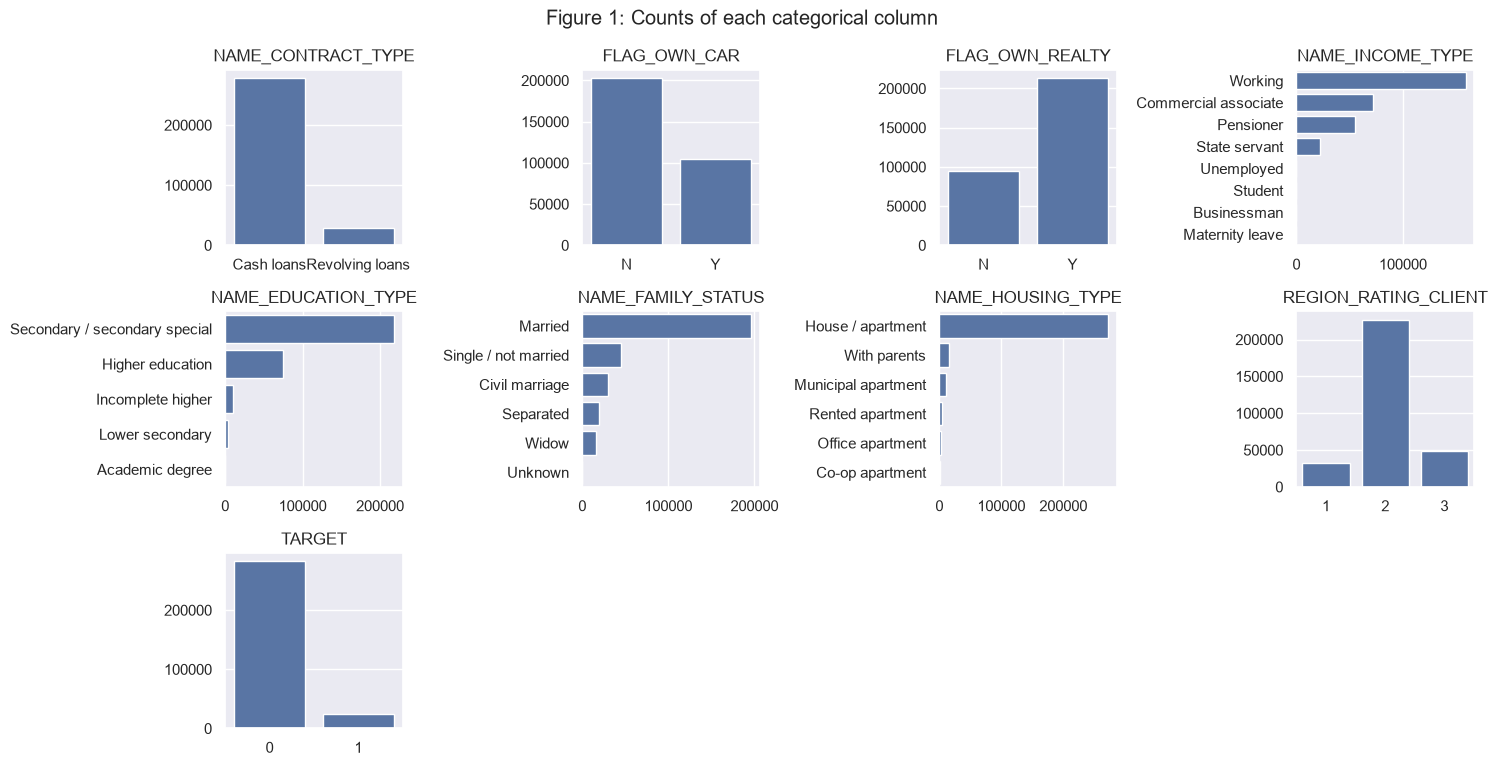

In [16]:
cols = [c for c in df_app.columns if c != "TARGET"]
categorical_cols = [
    "NAME_CONTRACT_TYPE", "FLAG_OWN_CAR", "FLAG_OWN_REALTY", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "REGION_RATING_CLIENT", "TARGET",
]
horizontal_cols = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE"]  # long labels
continuous_cols = [c for c in cols if c not in categorical_cols]


def grid(n, n_cols=4, height=2.6):
    """A grid of axes with room for n plots; spare axes hidden."""
    n_rows = -(-n // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, height * n_rows))
    axes = axes.ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes


fig, axes = grid(len(categorical_cols))
for ax, col in zip(axes, categorical_cols):
    s = df_app[col]
    if col in horizontal_cols:
        sns.countplot(y=s, order=s.value_counts().index, color="C0", ax=ax)
    else:
        sns.countplot(x=s, order=sorted(s.unique()), color="C0", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Figure 1: Counts of each categorical column")
fig.tight_layout()
plt.show()

- **Missing data:** Which columns are missing, and how often?

In [17]:
df_app[cols].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).map("{:.1%}".format)

OWN_CAR_AGE                   66.0%
EXT_SOURCE_1                  56.4%
EXT_SOURCE_3                  19.8%
YEARS_EMPLOYED                18.0%
AMT_REQ_CREDIT_BUREAU_YEAR    13.5%
AMT_REQ_CREDIT_BUREAU_QRT     13.5%
AMT_REQ_CREDIT_BUREAU_MON     13.5%
termMonths                     9.5%
OBS_30_CNT_SOCIAL_CIRCLE       0.3%
DEF_30_CNT_SOCIAL_CIRCLE       0.3%
EXT_SOURCE_2                   0.2%
AMT_GOODS_PRICE                0.1%
creditToGoods                  0.1%
AMT_ANNUITY                    0.0%
annuityToIncome                0.0%
YEARS_LAST_PHONE_CHANGE        0.0%
dtype: str

`EXT_SOURCE_1` is missing for 56% of applicants and `EXT_SOURCE_3` for 20%. These turn out to be the strongest predictors in the data, so their missing flags matter: if a score was only bought for some applicants, the gap itself carries information. `YEARS_EMPLOYED` is missing for 18%, which is exactly the placeholder rows above.

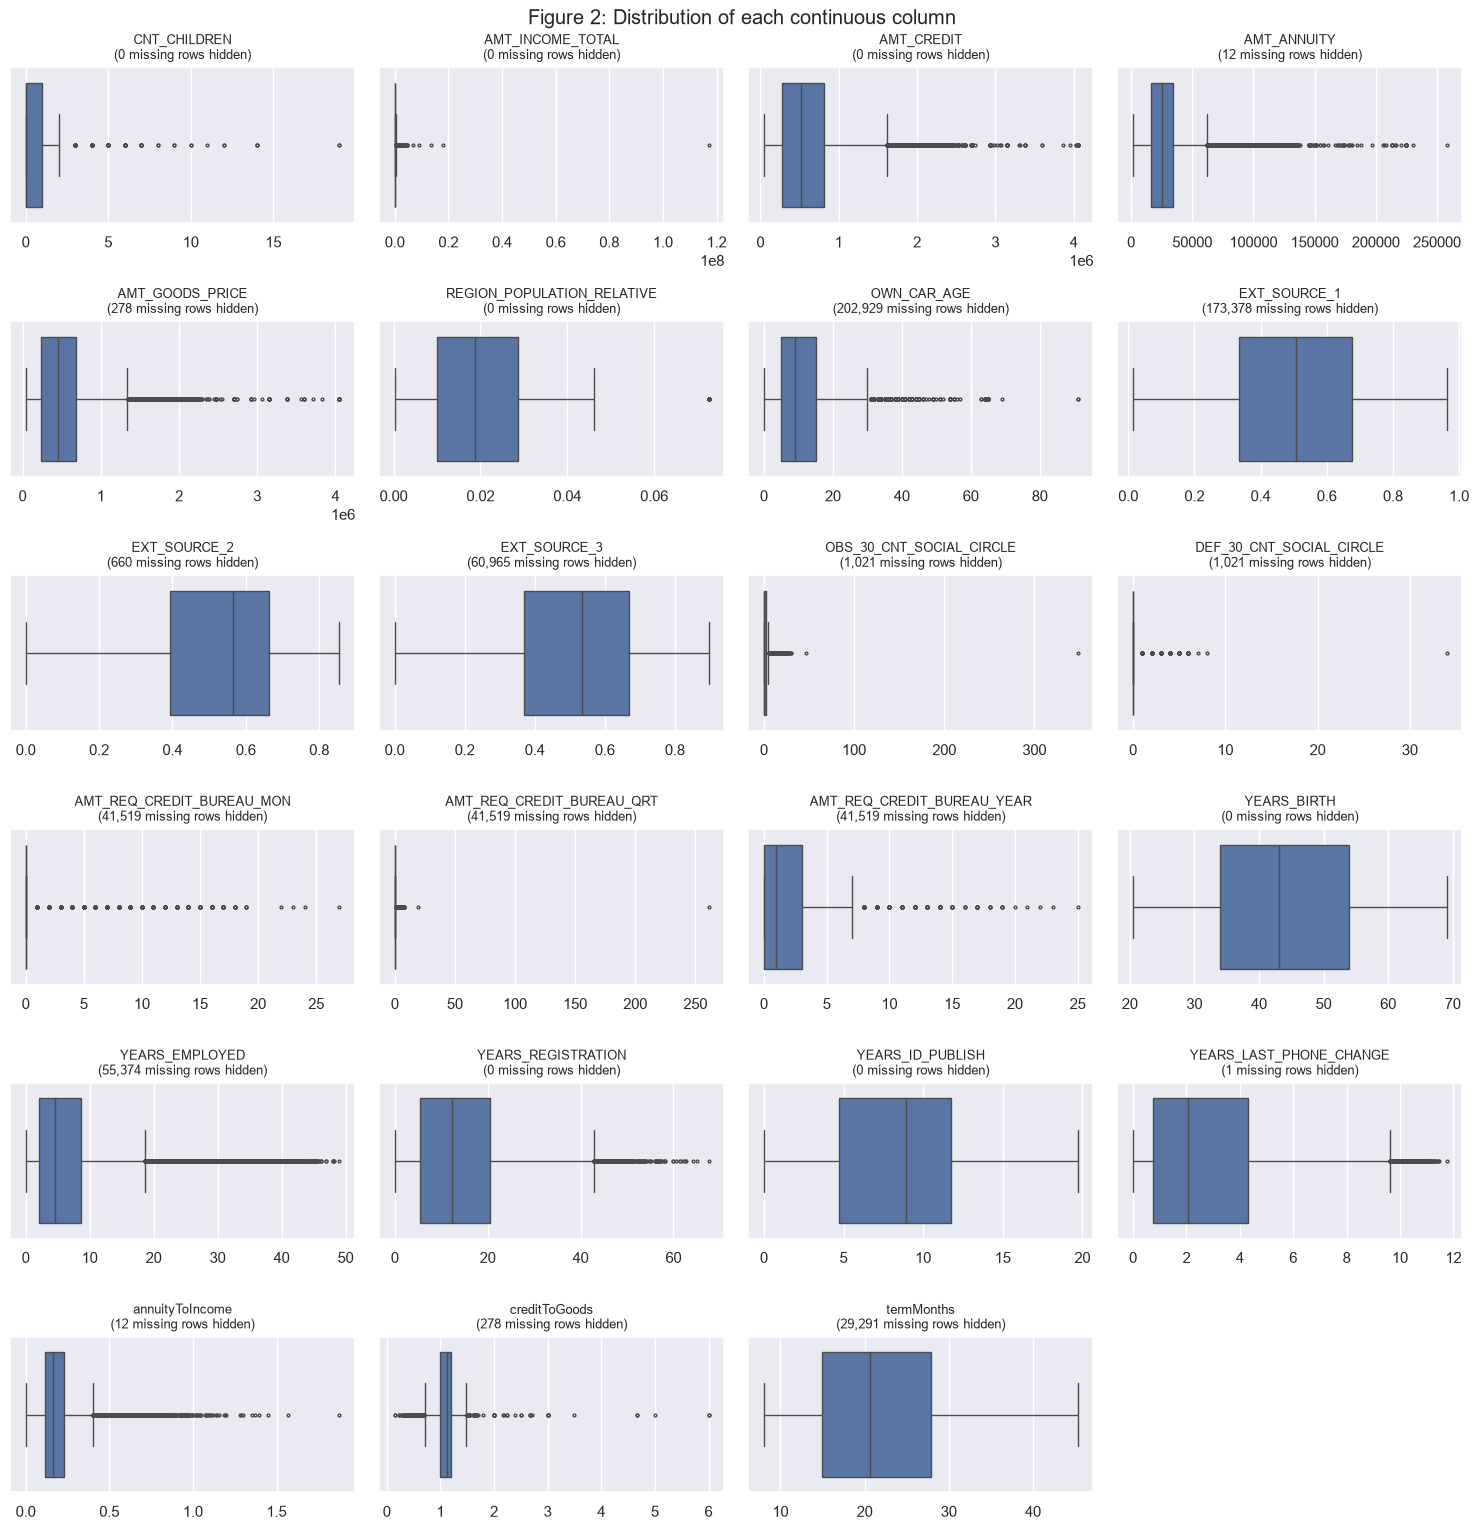

In [18]:
fig, axes = grid(len(continuous_cols))
for ax, col in zip(axes, continuous_cols):
    s = df_app[col]
    sns.boxplot(x=s.dropna(), color="C0", fliersize=2, ax=ax)
    ax.set_title(f"{col}\n({s.isna().sum():,} missing rows hidden)", fontsize=9)
    ax.set_xlabel("")

fig.suptitle("Figure 2: Distribution of each continuous column")
fig.tight_layout()
plt.show()

Every money column is right-skewed, and a few columns have single extreme values: one income of 117M, a social-circle count of 348 and a quarterly enquiry count of 261. That's why log and spline forms are tested in the linearity check rather than assuming linear.

## 2. Leakage and redundancy audit

It's vital we ensure that leakage isn't present when predicting future events. Furthermore, feature correlation can harm the performance of some methods, such as logistic regression.

- **Time leakage:** a quick check that no bureau record is dated after the application.

In [19]:
pd.Series({
    "bureau credits opened after application": (df_bureau["DAYS_CREDIT"] > 0).sum(),
    "bureau credits closed after application": (df_bureau["DAYS_ENDDATE_FACT"] > 0).sum(),
    "bureau_balance months after application": (df_bb["MONTHS_BALANCE"] > 0).sum(),
    "previous applications decided after application": (df_prev["DAYS_DECISION"] > 0).sum(),
    "instalments due after application": (df_inst["DAYS_INSTALMENT"] > 0).sum(),
    "instalments paid after application": (df_inst["DAYS_ENTRY_PAYMENT"] > 0).sum(),
    "POS / cash months after application": (df_pos["MONTHS_BALANCE"] > 0).sum(),
    "card months after application": (df_cc["MONTHS_BALANCE"] > 0).sum(),
})

bureau credits opened after application            0
bureau credits closed after application            0
bureau_balance months after application            0
previous applications decided after application    0
instalments due after application                  0
instalments paid after application                 0
POS / cash months after application                0
card months after application                      0
dtype: int64

In [20]:
account_types = ["Consumer credit", "Credit card", "Other"]


def label_credit_type(bureau):
    """Credit types beyond the two most common (car loans, mortgages, microloans, ...) are grouped as Other."""
    is_common = bureau["CREDIT_TYPE"].isin(account_types[:2])
    return bureau.assign(account_type=bureau["CREDIT_TYPE"].where(is_common, "Other"))


def drop_after_application(bureau, bb):
    after = (bureau["DAYS_CREDIT"] > 0) | (bureau["DAYS_ENDDATE_FACT"] > 0)
    return bureau[~after], bb[bb["MONTHS_BALANCE"] <= 0]


df_bureau, df_bb = drop_after_application(label_credit_type(df_bureau), df_bb)


def drop_history_after_application(prev, inst, pos, cc):
    after_due = inst["DAYS_INSTALMENT"] > 0
    after_paid = inst["DAYS_ENTRY_PAYMENT"] > 0  # NaN (unpaid) is kept
    return (prev[prev["DAYS_DECISION"] <= 0], inst[~after_due & ~after_paid],
            pos[pos["MONTHS_BALANCE"] <= 0], cc[cc["MONTHS_BALANCE"] <= 0])


df_prev, df_inst, df_pos, df_cc = drop_history_after_application(df_prev, df_inst, df_pos, df_cc)

`DAYS_CREDIT_ENDDATE` can be positive, but that is the *planned* end date, known at application, so it's not leakage.

- **Overlap:** `AMT_REQ_CREDIT_BUREAU_*` counts enquiries, and `bureau.csv` counts credits actually opened, so they measure different things. The mutual-information check in section 7 will flag them if they turn out to be redundant.

## 3. The target and its rates

In [21]:
def plot_heatmap(grouped, xlabel, ylabel, title):
    """Default-rate heatmap of a two-key groupby (rows = 1st key, cols = 2nd), with "All" margins."""
    s = grouped["TARGET"].agg(["sum", "size"])
    k, n = (s[c].unstack(fill_value=0) for c in ("sum", "size"))  # defaults, all applications
    for t in (k, n):
        t.index = t.index.astype(str)
        t.columns = t.columns.astype(str)
        t["All"] = t.sum(axis=1)
        t.loc["All"] = t.sum()
    rate = k / n  # margins pool every application in the row/column, not a mean of cells
    labels = (rate.map("{:.1%}".format) + "\n" + n.map("n={}".format)).where(n > 0, "")

    fig, ax = plt.subplots(figsize=(13, 5.5))
    sns.heatmap(rate, annot=labels, fmt="", cmap="Reds", linewidths=2, linecolor="white",
                cbar_kws={"format": mpl.ticker.PercentFormatter(1, decimals=1), "label": "Default rate"},
                annot_kws={"fontsize": 8}, ax=ax)
    ax.axhline(len(rate) - 1, color="black", lw=2)  # set the "All" margins apart from the grid
    ax.axvline(len(rate.columns) - 1, color="black", lw=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


score_bin = pd.qcut(df_app["EXT_SOURCE_2"], q=10)  # risk-score deciles

- **Term × risk score (H4)**

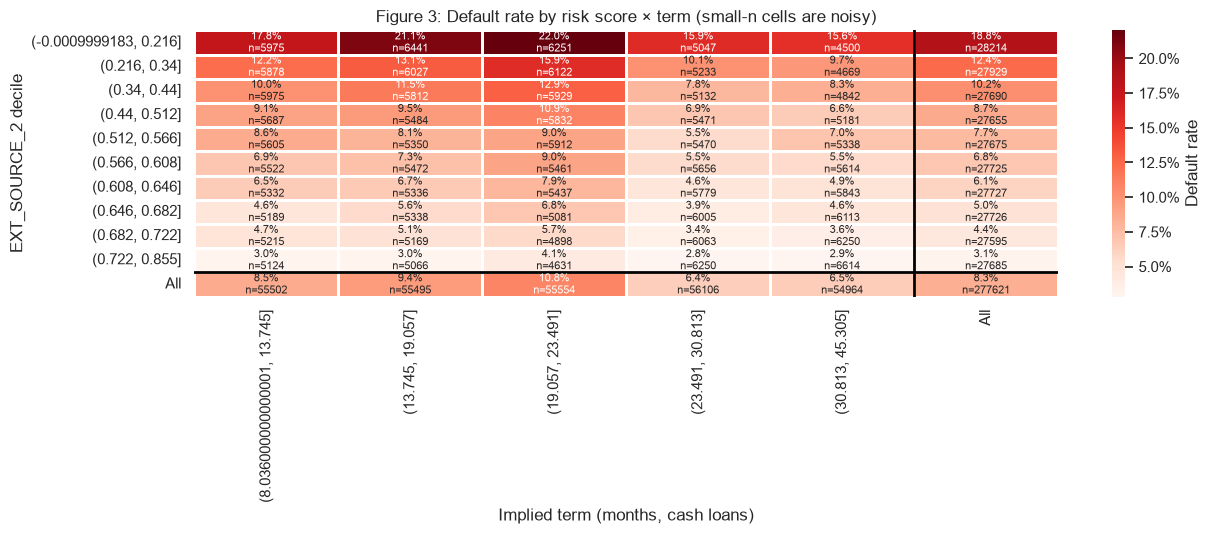

In [22]:
term_bin = pd.qcut(df_app["termMonths"], q=5)
plot_heatmap(df_app.groupby([score_bin, term_bin], observed=True), "Implied term (months, cash loans)",
             "EXT_SOURCE_2 decile", "Figure 3: Default rate by risk score × term (small-n cells are noisy)")

No. Across all scores, default peaks at implied terms of 19–23 months (10.8%) and is lowest for the longest loans (6.4–6.5% beyond 23 months). The same shape holds within almost every score row, so it isn't just riskier applicants taking shorter loans. **H4 looks wrong as stated.** The likely explanation is selection: the lender only offers long terms to applicants it already trusts, using information the score doesn't capture.

- **Affordability × risk score (H1)**

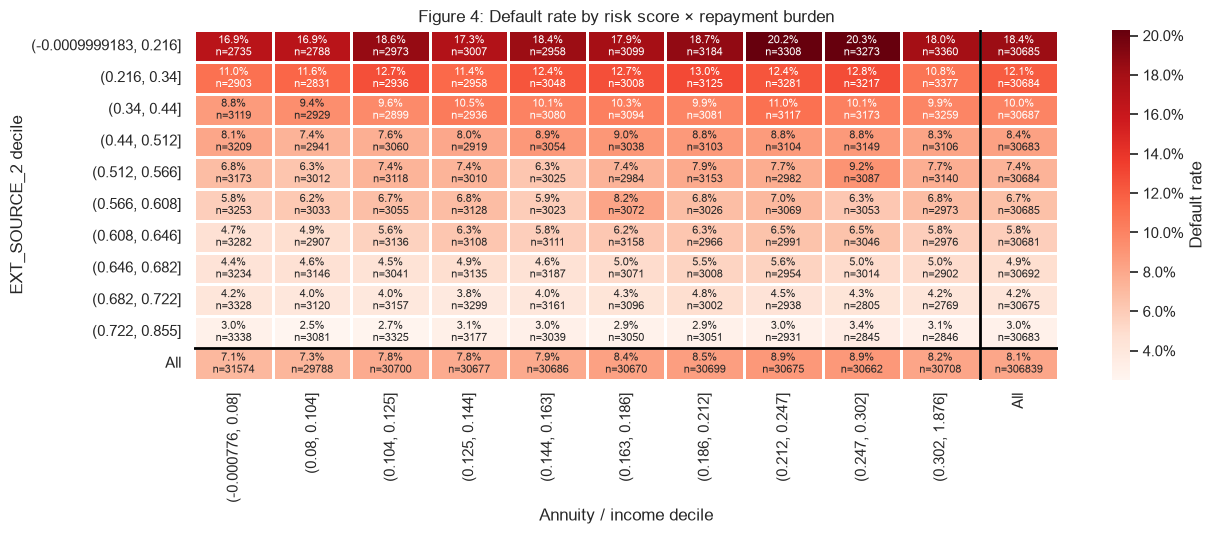

In [23]:
burden_bin = pd.qcut(df_app["annuityToIncome"], q=10)
plot_heatmap(df_app.groupby([score_bin, burden_bin], observed=True), "Annuity / income decile",
             "EXT_SOURCE_2 decile", "Figure 4: Default rate by risk score × repayment burden")

The raw effect is small: the "All" row rises from 7.1% to 8.9% across the bottom nine burden deciles, then dips to 8.2% in the top decile. Within score rows the gradient is steepest for the riskiest decile (16.9% → 20.3%) and flat for the safest (2.5–3.4% throughout). So burden adds risk once the score is fixed, mostly among applicants who are already risky: **weak support for H1**.

- **Income type × home ownership (H3)**

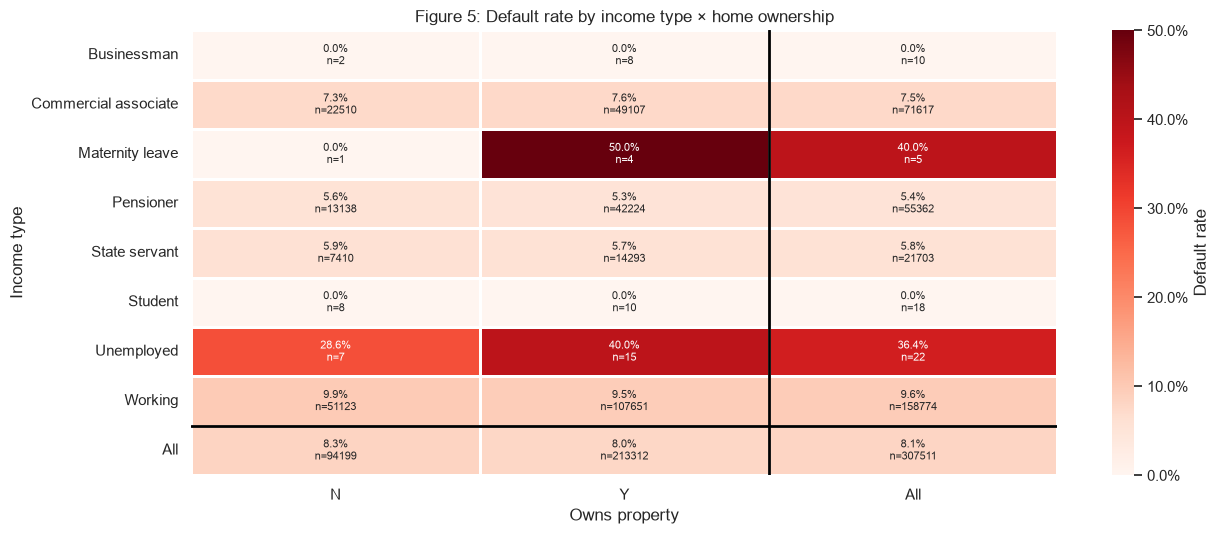

In [24]:
plot_heatmap(df_app.groupby(["NAME_INCOME_TYPE", "FLAG_OWN_REALTY"]), "Owns property",
             "Income type", "Figure 5: Default rate by income type × home ownership")

Owning property barely matters: 8.0% for owners vs 8.3% for non-owners, with a similar gap within each income type. Pensioners default at 5.4% vs 9.6% for working applicants, and owner and non-owner pensioners are almost identical (5.3% vs 5.6%). So **H3 is half right**: pensioners ↓ yes, homeowners ↓ no, and none of the expected interaction. (The Unemployed, Maternity leave, Student and Businessman rows each have fewer than 25 applicants, so ignore them.)

## 4. Categorical screening

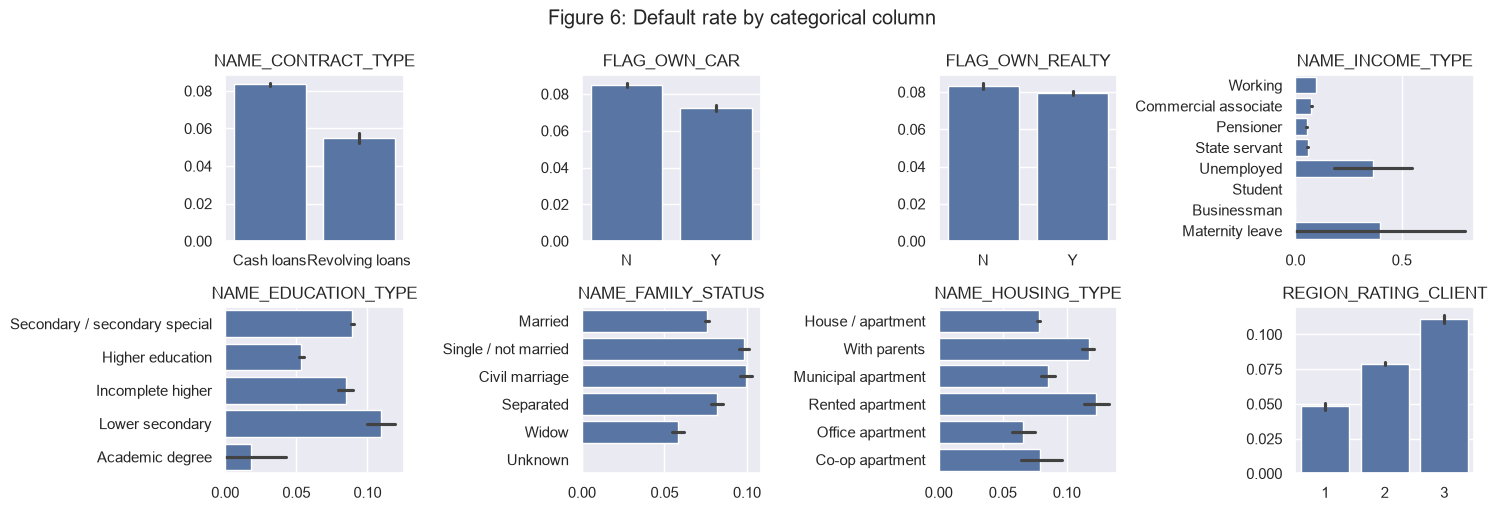

In [25]:
cols_to_plot = [c for c in categorical_cols if c != "TARGET"]

fig, axes = grid(len(cols_to_plot))
for ax, col in zip(axes, cols_to_plot):
    s = df_app[col]
    if col in horizontal_cols:
        sns.barplot(data=df_app, y=col, x="TARGET", order=s.value_counts().index, color="C0", ax=ax)
    else:
        sns.barplot(data=df_app, x=col, y="TARGET", order=sorted(s.unique()), color="C0", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Figure 6: Default rate by categorical column")
fig.tight_layout()
plt.show()

## 5. Continuous screening

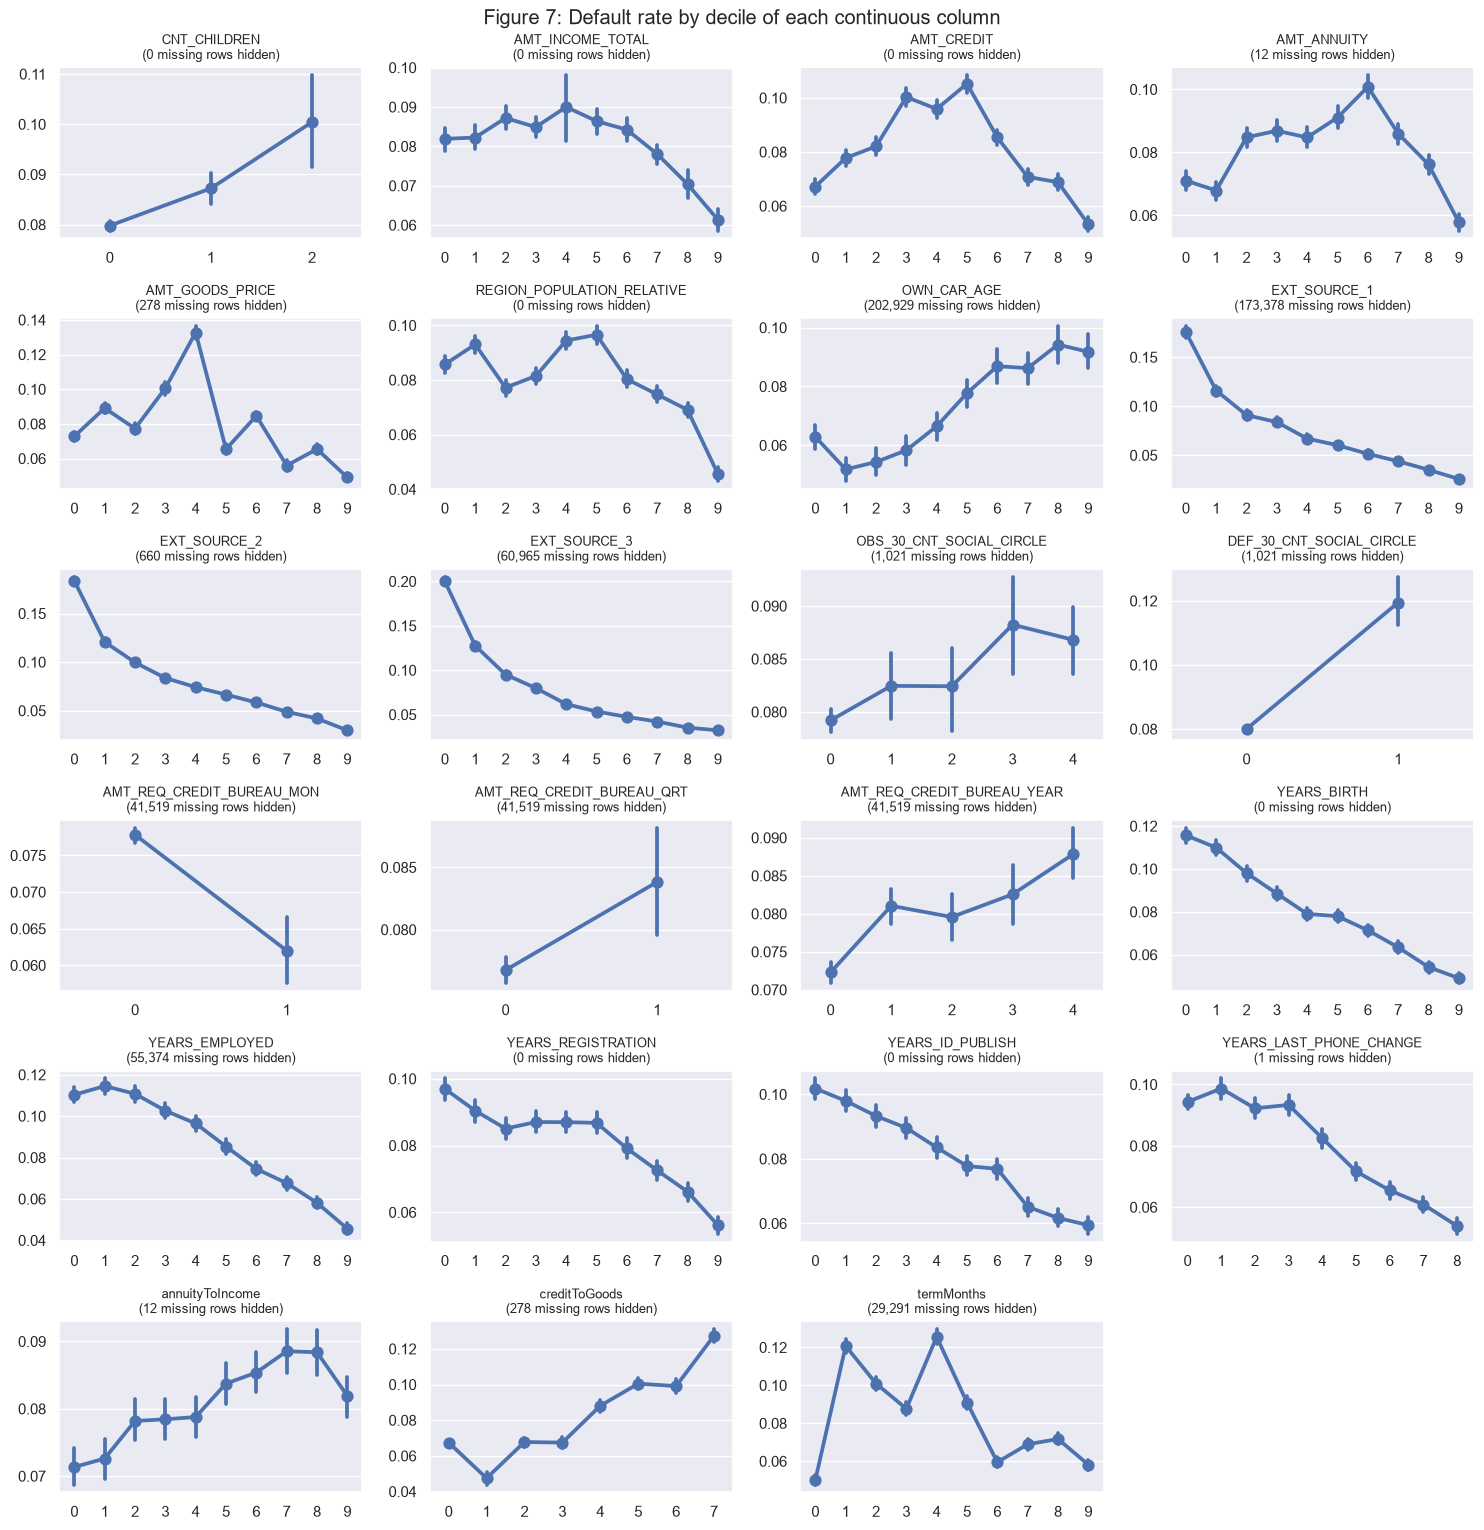

In [26]:
fig, axes = grid(len(continuous_cols))
for ax, col in zip(axes, continuous_cols):
    s = df_app[col].dropna()
    decile = pd.qcut(s, q=10, labels=False, duplicates="drop")
    sns.pointplot(x=decile, y=target.loc[s.index], color="C0", ax=ax)
    ax.set_title(f"{col}\n({df_app[col].isna().sum():,} missing rows hidden)", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Figure 7: Default rate by decile of each continuous column")
fig.tight_layout()
plt.show()

**Monotone:** the three `EXT_SOURCE` scores (about 18–20% default in the lowest decile down to about 3% in the highest), age (`YEARS_BIRTH`, 11.6% → 4.9%), `YEARS_EMPLOYED`, `YEARS_ID_PUBLISH` and `YEARS_LAST_PHONE_CHANGE`: longer is safer for all of them. `creditToGoods` rises steadily from about 5% to 13%, so financing more than the goods cost is a warning sign.

**Not monotone:** `AMT_CREDIT`, `AMT_ANNUITY` and `AMT_GOODS_PRICE` peak in the middle deciles; `termMonths` is jagged (5% in the shortest decile, about 12% in deciles 1 and 4); `annuityToIncome` rises and then dips in the top decile. These need splines.

The final check is how correlated these features are.

## 6. Bureau-specific features

- **Rebuild:** `bureau_balance.csv` has one row per *credit* per month. An applicant can hold several credits of the same type, so I aggregate to one row per applicant / credit type / month and keep the worst status. This is the same fan-out problem as joining applicant → credits → months.

In [27]:
def aggregate_monthly(bb, bureau):
    """One row per applicant / credit type / month; credits of the same type and month are combined, keeping the worst status."""
    rows = bb.merge(bureau[["SK_ID_BUREAU", "SK_ID_CURR", "account_type"]], on="SK_ID_BUREAU")
    agg = (rows.assign(severity=rows["STATUS"].cat.codes)
           .groupby(["SK_ID_CURR", "account_type", "MONTHS_BALANCE"], as_index=False)
           .agg(n_accounts=("SK_ID_BUREAU", "size"), severity=("severity", "max")))
    agg["max_status"] = pd.Categorical.from_codes(agg.pop("severity"), dtype=status_dtype)
    return agg


agg = aggregate_monthly(df_bb, df_bureau)
agg

,SK_ID_CURR,account_type,MONTHS_BALANCE,n_accounts,max_status
0,100001,Consumer credit,-51,1,X
1,100001,Consumer credit,-50,1,X
2,100001,Consumer credit,-49,1,X
3,100001,Consumer credit,-48,1,X
4,100001,Consumer credit,-47,1,X
...,...,...,...,...,...
10522305,456255,Credit card,-4,1,0
10522306,456255,Credit card,-3,1,0
10522307,456255,Credit card,-2,1,C
10522308,456255,Credit card,-1,1,C


- **Status summary:** the share of months each credit type spent in each status bucket.

In [28]:
def plot_rate(ax, groups, order, title, min_n=30):
    n = groups.value_counts()
    order = [g for g in order if n.get(g, 0) >= min_n]  # tiny groups only add huge CIs
    sns.barplot(x=groups, y=target, order=order, color="C0", ax=ax)
    ax.set_xticks(range(len(order)), [f"{g}\nn={n[g]}" for g in order], fontsize=7)
    ax.axhline(target.mean(), color="grey", ls="--", lw=1)
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")


def bin_shares(share, held):
    nonzero = pd.qcut(share[share > 0], 4, duplicates="drop")
    labels = {iv: f"{max(iv.left, 0):.0%}-{iv.right:.0%}" for iv in nonzero.cat.categories}
    binned = (pd.Series("0%", index=share.index).mask(share > 0, nonzero.map(labels).astype(str))
              .mask(~held, "none"))
    return binned, ["none", "0%", *dict.fromkeys(labels.values())]


buckets = ["0", "1-2", "3-5", "C", "X"]

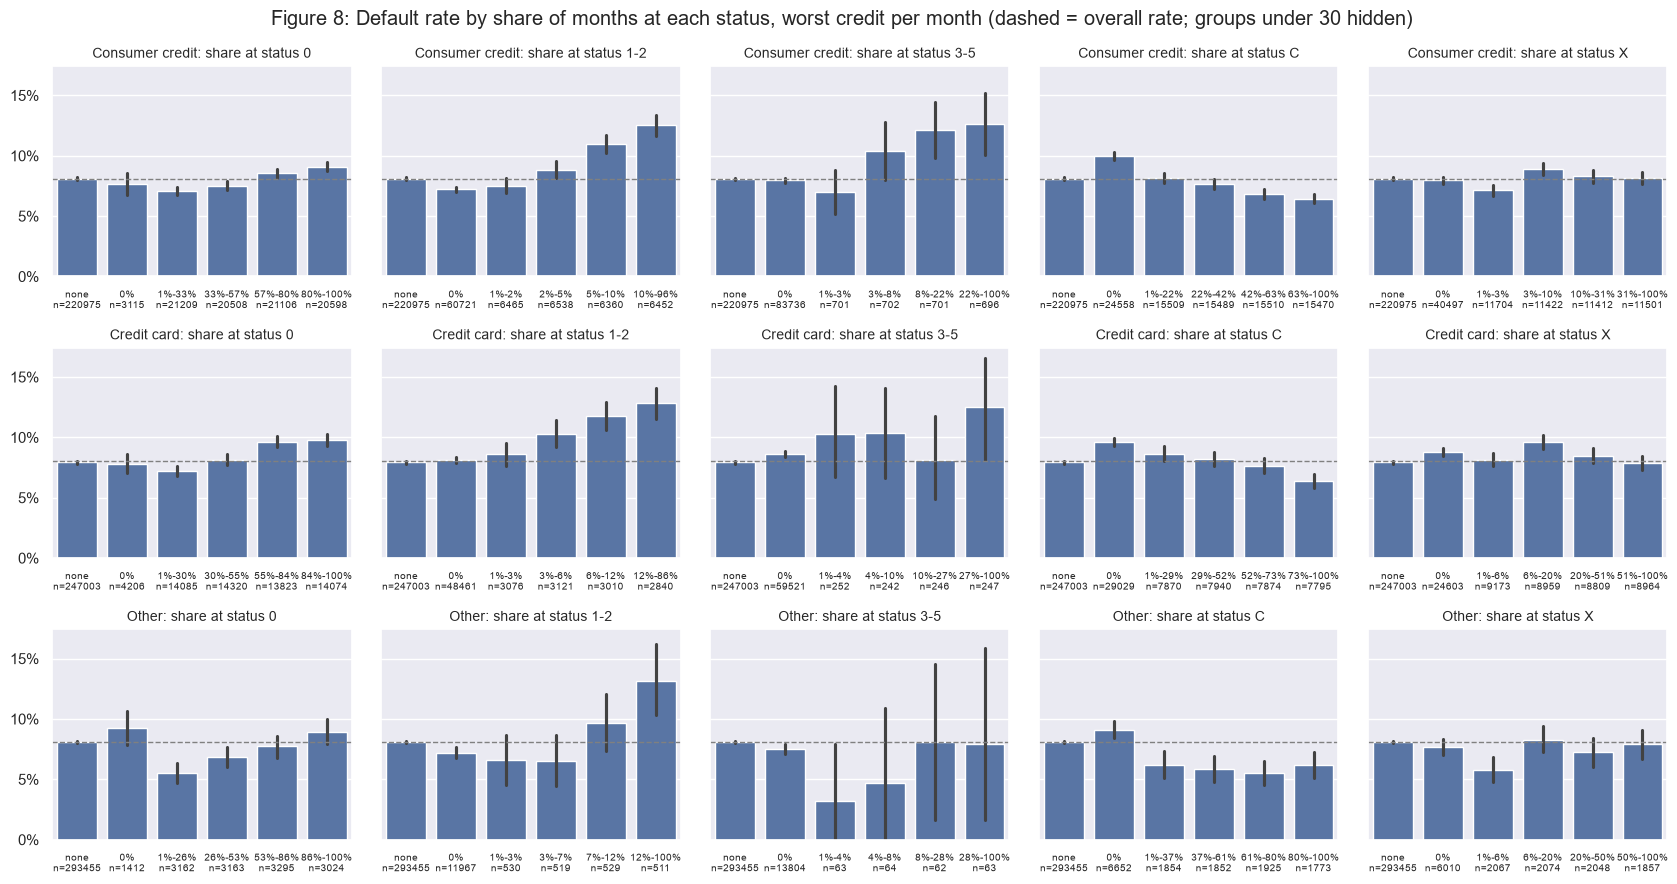

In [29]:
def build_status_shares(agg, ids):
    """Per credit type, the share of months in each status bucket (worst credit per month)."""
    status_bucket = {"0": "0", "1": "1-2", "2": "1-2", "3": "3-5", "4": "3-5", "5": "3-5", "C": "C", "X": "X"}
    status = agg["max_status"].astype(str).map(status_bucket).rename("status")
    status_counts = (agg.groupby(["SK_ID_CURR", "account_type", status]).size()
                     .unstack(["account_type", "status"], fill_value=0).sort_index(axis=1))
    assert status_counts.to_numpy().sum() == len(agg)  # every applicant-type-month lands in exactly one bucket.

    months_on_file = status_counts.T.groupby(level="account_type").sum().T  # months on file per type.
    status_shares = status_counts.div(months_on_file, level="account_type")
    status_shares.columns = [f"{t}_status_{b}_share" for t, b in status_shares.columns]
    return status_shares.reindex(ids).fillna(0)


df_tl_status = build_status_shares(agg, df_app.index)

fig, axes = plt.subplots(len(account_types), len(buckets), figsize=(17, 9), sharey=True)
for row, account_type in zip(axes, account_types):
    held = df_tl_status.filter(like=f"{account_type}_status_").sum(axis=1) > 0
    for ax, bucket in zip(row, buckets):
        col = f"{account_type}_status_{bucket}_share"
        if col not in df_tl_status:
            ax.set_visible(False)
            continue
        binned, order = bin_shares(df_tl_status[col], held)
        plot_rate(ax, binned, order, f"{account_type}: share at status {bucket}")
fig.suptitle("Figure 8: Default rate by share of months at each status, worst credit per month (dashed = overall rate; groups under 30 hidden)")
fig.tight_layout()
plt.show()

- **Early payoffs (H2):** a closed, fixed-term credit whose actual end date came more than a month before its planned end. Credit cards have no planned end, so they're excluded. In the original analysis this kind of feature, mined from the account history, was one of the strongest signals.

In [30]:
def build_early_payoffs(bureau, ids):
    """Count of credits paid off more than 30 days early, and months since the latest one (NaN = never)."""
    closed = bureau[(bureau["CREDIT_ACTIVE"] == "Closed") & (bureau["account_type"] != "Credit card")]
    planned_ok = closed["DAYS_CREDIT_ENDDATE"] > closed["DAYS_CREDIT"]  # some planned ends precede the start: unusable
    early = closed[planned_ok & (closed["DAYS_ENDDATE_FACT"] < closed["DAYS_CREDIT_ENDDATE"] - 30)]

    by_applicant = early.groupby("SK_ID_CURR")
    payoff = pd.DataFrame({
        "bureauEarlyPayoffs": by_applicant.size(),
        "monthsSinceBureauEarlyPayoff": -by_applicant["DAYS_ENDDATE_FACT"].max() / 30.44,
    }).reindex(ids)
    return payoff.fillna({"bureauEarlyPayoffs": 0})


df_tl_payoff = build_early_payoffs(df_bureau, df_app.index)

- **Outstanding balances:** `bureau_balance.csv` has no balances, so the balance level comes from the bureau snapshot: per credit type, the number of active credits and their outstanding debt.

In [31]:
def build_balance_features(bureau, ids):
    """Per credit type: number of active credits and their outstanding debt, as last reported to the bureau."""
    active = bureau[bureau["CREDIT_ACTIVE"] == "Active"]
    per_type = active.groupby(["SK_ID_CURR", "account_type"]).agg(
        nActive=("SK_ID_BUREAU", "size"),
        debtActive=("AMT_CREDIT_SUM_DEBT", "sum"),
    ).unstack()
    per_type.columns = [f"{t}_{f}" for f, t in per_type.columns]
    return per_type.reindex(ids).fillna(0)


df_tl_balance = build_balance_features(df_bureau, df_app.index)

- **Missed-payment recency, account history and credit seeking:** the status shares ignore *when* problems happened. So I add months since the last missed payment (status 1–5, any type), and per type the number of credits ever held, months on file and the most credits held at once. For H2, I also add credits opened in the last 12 months and credits overdue right now.

In [32]:
def build_history_features(agg, bureau, ids):
    # Months since the last missed payment on any credit. Shares say how often, not how recently.
    missed = agg[agg["max_status"] >= "1"]
    months_since_missed = -missed.groupby("SK_ID_CURR")["MONTHS_BALANCE"].max()

    credits = bureau.groupby(["SK_ID_CURR", "account_type"]).size().unstack(fill_value=0)
    credits.columns = [f"{t}_nCredits" for t in credits.columns]
    months = agg.groupby(["SK_ID_CURR", "account_type"]).agg(
        monthsOnFile=("n_accounts", "size"),
        nAccountsMax=("n_accounts", "max"),
    ).unstack()
    months.columns = [f"{t}_{f}" for f, t in months.columns]

    history = credits.join(months, how="outer").reindex(ids).fillna(0)
    return history.assign(
        monthsSinceLastMissedPayment=months_since_missed,  # NaN = never missed
        bureauOpenedLast12Months=bureau[bureau["DAYS_CREDIT"] > -365].groupby("SK_ID_CURR").size(),
        bureauOverdueNow=bureau[bureau["AMT_CREDIT_SUM_OVERDUE"] > 0].groupby("SK_ID_CURR").size(),
    ).fillna({"bureauOpenedLast12Months": 0, "bureauOverdueNow": 0})


df_tl_history = build_history_features(agg, df_bureau, df_app.index)

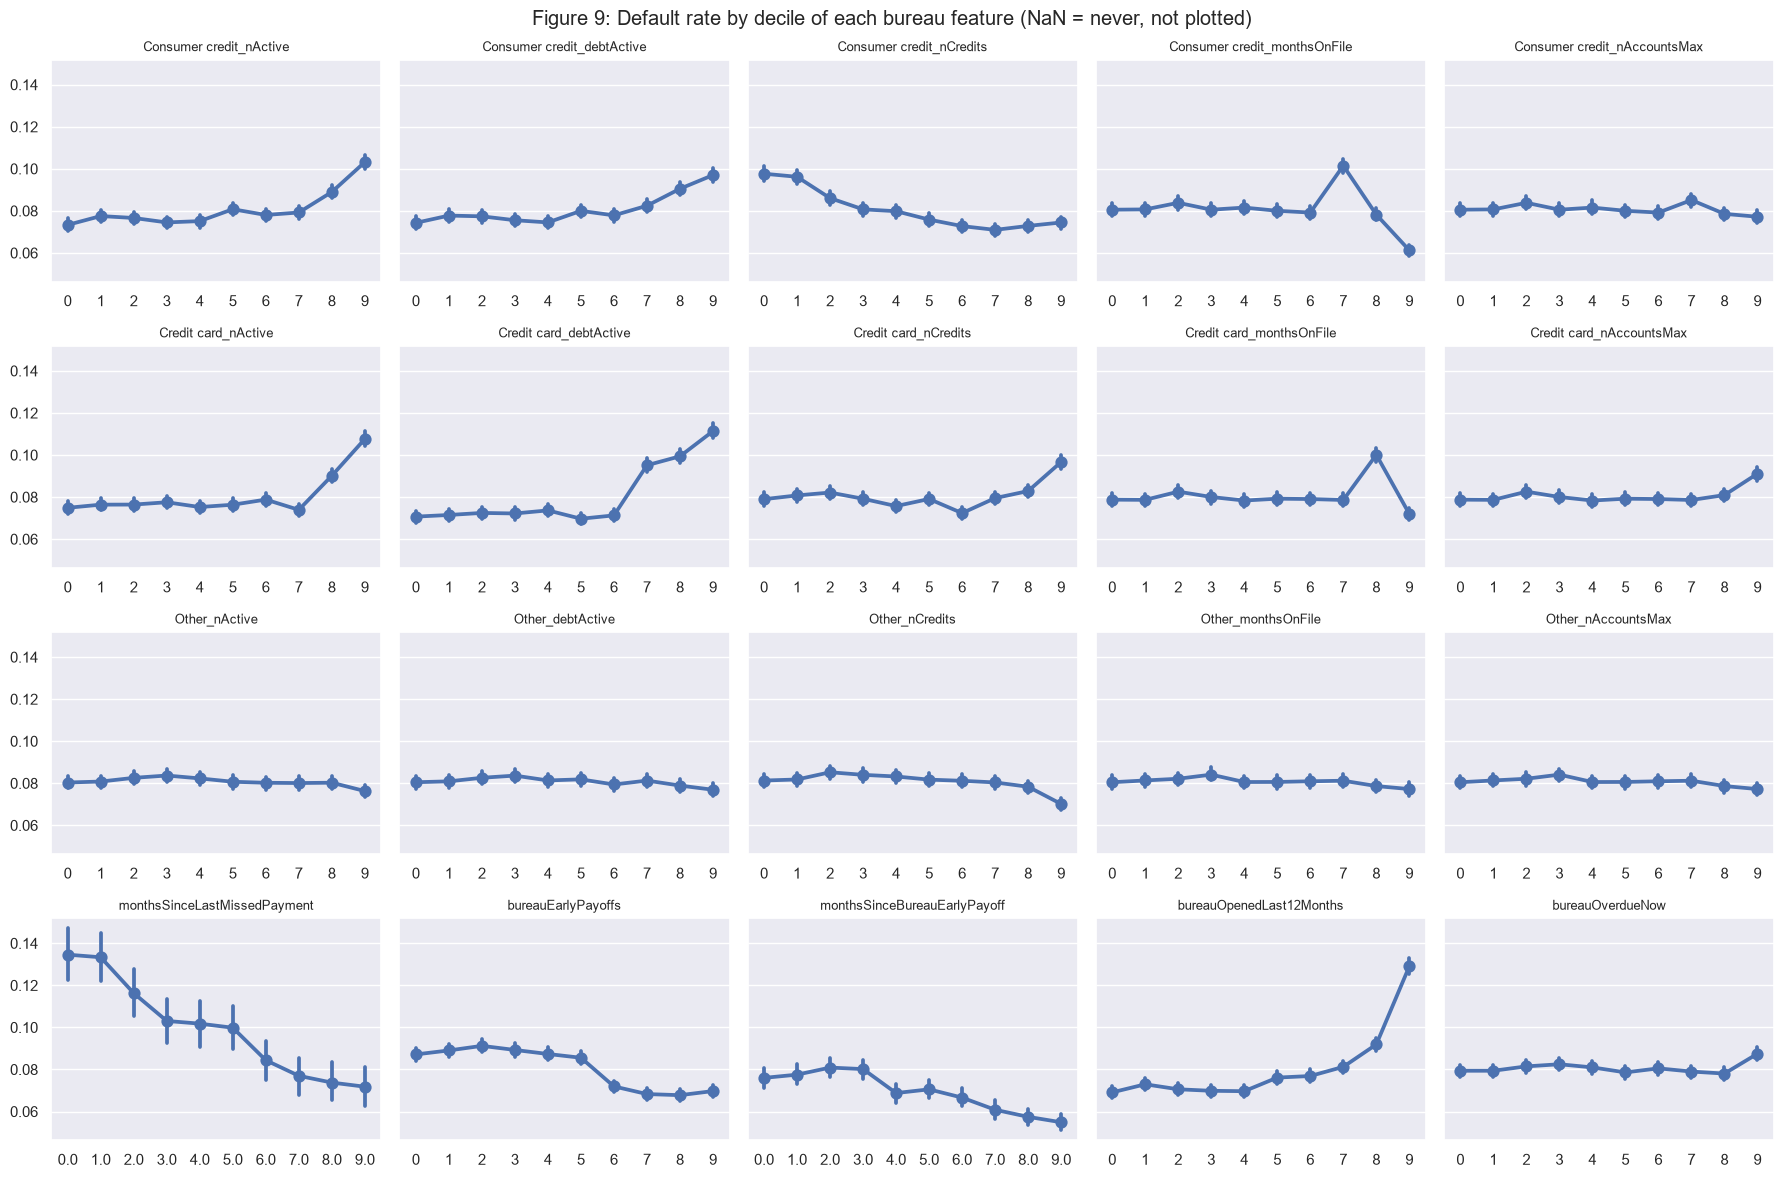

In [33]:
df_tl_new = df_tl_payoff.join(df_tl_balance).join(df_tl_history)

# One row of plots per credit type, then the applicant-level features.
plot_rows = [[c for c in df_tl_new.columns if c.startswith(account_type)] for account_type in account_types]
plot_rows.append(["monthsSinceLastMissedPayment", "bureauEarlyPayoffs", "monthsSinceBureauEarlyPayoff",
                  "bureauOpenedLast12Months", "bureauOverdueNow"])

n_cols = max(len(row_cols) for row_cols in plot_rows)
fig, axes = plt.subplots(len(plot_rows), n_cols, figsize=(18, 3 * len(plot_rows)), sharey=True)

for ax_row, row_cols in zip(axes, plot_rows):
    for ax, col in zip(ax_row, row_cols):
        s = df_tl_new[col]
        decile = pd.qcut(s.rank(method="first"), q=10, labels=False)  # rank so ties can't merge deciles.
        sns.pointplot(x=decile, y=target, color="C0", ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in ax_row[len(row_cols):]:
        ax.set_visible(False)

fig.suptitle("Figure 9: Default rate by decile of each bureau feature (NaN = never, not plotted)")
fig.tight_layout()
plt.show()

**H2 holds.** The top decile of credits opened in the last 12 months defaults at 12.9% vs about 7% for the bottom half. Early payoffs point the other way: applicants with the most early payoffs default at about 7% vs about 9% for those with few or none. Recency of missed payments matters a lot: a miss in the last few months means about 13% default, falling to about 7% when the last miss was long ago. Active debt matters mainly for credit cards, where the top three deciles run at 9.5–11%. The `Other` credit types (car loans, mortgages, microloans) are flat throughout, so they carry little signal.

## 7. Previous Home Credit loans

The bureau shows other lenders' view of the applicant; these four tables show Home Credit's own. Each gets a handful of summaries, built the same way as the bureau features: aggregate to one row per applicant, and keep "no records" apart from zero.

- **Previous applications (H5):** how often Home Credit refused the applicant, how often it approved them only at a high price (`NAME_YIELD_GROUP`), how much of what they asked for they were given, and how recently they last applied.

In [34]:
def build_previous_features(prev, ids):
    """Home Credit's past decisions on the applicant (NaN = no previous applications)."""
    approved = prev["NAME_CONTRACT_STATUS"] == "Approved"
    asked = prev["AMT_APPLICATION"].where(prev["AMT_APPLICATION"] > 0)
    rows = prev.assign(
        refused=prev["NAME_CONTRACT_STATUS"] == "Refused",
        high_yield=(prev["NAME_YIELD_GROUP"] == "high").astype(float).where(approved),  # approved loans only
        given_to_asked=(prev["AMT_CREDIT"] / asked).where(approved),
    )
    by_applicant = rows.groupby("SK_ID_CURR")
    return pd.DataFrame({
        "prevApplications": by_applicant.size(),
        "prevRefusedShare": by_applicant["refused"].mean(),
        "prevHighYieldShare": by_applicant["high_yield"].mean(),
        "prevCreditToAsked": by_applicant["given_to_asked"].mean(),  # < 1 = given less than asked for
        "prevMonthsSinceLast": -by_applicant["DAYS_DECISION"].max() / 30.44,
    }).reindex(ids)

- **Instalments (H6):** first collapse the fan-out to one row per instalment, with partial payments summed and the last payment date kept. Then, per applicant: the share of instalments paid late, paid short, or paid at least a week early, and months since the last late one.

In [35]:
def collapse_instalments(inst):
    """One row per instalment. Unpaid at application counts as paid at application (day 0), i.e. late."""
    return (inst.groupby(["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"], as_index=False)
            .agg(due=("DAYS_INSTALMENT", "first"), owed=("AMT_INSTALMENT", "first"),
                 paid=("AMT_PAYMENT", "sum"), paid_on=("DAYS_ENTRY_PAYMENT", "max"))
            .fillna({"paid_on": 0}))


def build_instalment_features(inst, ids):
    """How the applicant repaid previous Home Credit loans (NaN = no instalments)."""
    days_late = inst["paid_on"] - inst["due"]
    rows = inst.assign(late=days_late > 0, short=inst["paid"] < inst["owed"] - 1, early=days_late <= -7)
    by_applicant = rows.groupby("SK_ID_CURR")
    return pd.DataFrame({
        "instCount": by_applicant.size(),
        "instLateShare": by_applicant["late"].mean(),
        "instShortShare": by_applicant["short"].mean(),  # paid less than owed (1 unit of rounding allowed)
        "instEarlyShare": by_applicant["early"].mean(),  # paid at least a week before the due date
        "instMonthsSinceLate": -rows[rows["late"]].groupby("SK_ID_CURR")["due"].max() / 30.44,  # NaN = never late
    }).reindex(ids)

- **POS / cash loans and cards (H6, H7):** for previous POS and cash loans, the share of months past due, how many are still active and how much of them is left to run. For cards, utilisation (balance / limit, summed over cards) in the latest month and over the last year, and the share of months the minimum payment was missed.

In [36]:
def build_pos_features(pos, ids):
    """Previous POS and cash loans, month by month (NaN = no records)."""
    latest = pos.sort_values("MONTHS_BALANCE").groupby("SK_ID_PREV").tail(1)  # each loan's latest month
    active = latest[latest["NAME_CONTRACT_STATUS"] == "Active"]
    remaining = active["CNT_INSTALMENT_FUTURE"] / active["CNT_INSTALMENT"].where(active["CNT_INSTALMENT"] > 0)
    by_applicant = pos.assign(past_due=pos["SK_DPD_DEF"] > 0).groupby("SK_ID_CURR")

    features = pd.DataFrame({
        "posMonthsOnFile": by_applicant.size(),
        "posPastDueShare": by_applicant["past_due"].mean(),
        "posActiveLoans": active.groupby("SK_ID_CURR").size(),
        "posRemainingShare": remaining.groupby(active["SK_ID_CURR"]).mean(),  # NaN = nothing active
    }).reindex(ids)
    features["posActiveLoans"] = features["posActiveLoans"].fillna(0).where(features["posMonthsOnFile"].notna())
    return features


def build_card_features(cc, ids):
    """Home Credit cards: cards held at once are summed per month first (NaN = no card)."""
    monthly = (cc.groupby(["SK_ID_CURR", "MONTHS_BALANCE"], as_index=False)
               .agg(balance=("AMT_BALANCE", "sum"), limit=("AMT_CREDIT_LIMIT_ACTUAL", "sum"),
                    paid=("AMT_PAYMENT_TOTAL_CURRENT", "sum"), minimum=("AMT_INST_MIN_REGULARITY", "sum")))
    monthly["utilisation"] = monthly["balance"] / monthly["limit"].where(monthly["limit"] > 0)
    monthly["missed_min"] = (monthly["paid"] < monthly["minimum"]).astype(float).where(monthly["minimum"] > 0)

    by_applicant = monthly.groupby("SK_ID_CURR")
    latest = monthly.loc[by_applicant["MONTHS_BALANCE"].idxmax()].set_index("SK_ID_CURR")
    last_year = monthly[monthly["MONTHS_BALANCE"] > -12]
    return pd.DataFrame({
        "cardMonthsOnFile": by_applicant.size(),
        "cardUtilisationLatest": latest["utilisation"],
        "cardUtilisationMean12m": last_year.groupby("SK_ID_CURR")["utilisation"].mean(),
        "cardMissedMinShare": by_applicant["missed_min"].mean(),  # of months with a minimum due
    }).reindex(ids)


def build_history(prev, inst, pos, cc, ids):
    """All Home Credit history features, one row per applicant."""
    return (build_previous_features(prev, ids)
            .join(build_instalment_features(collapse_instalments(inst), ids))
            .join(build_pos_features(pos, ids))
            .join(build_card_features(cc, ids)))


df_hc = build_history(df_prev, df_inst, df_pos, df_cc, df_app.index)

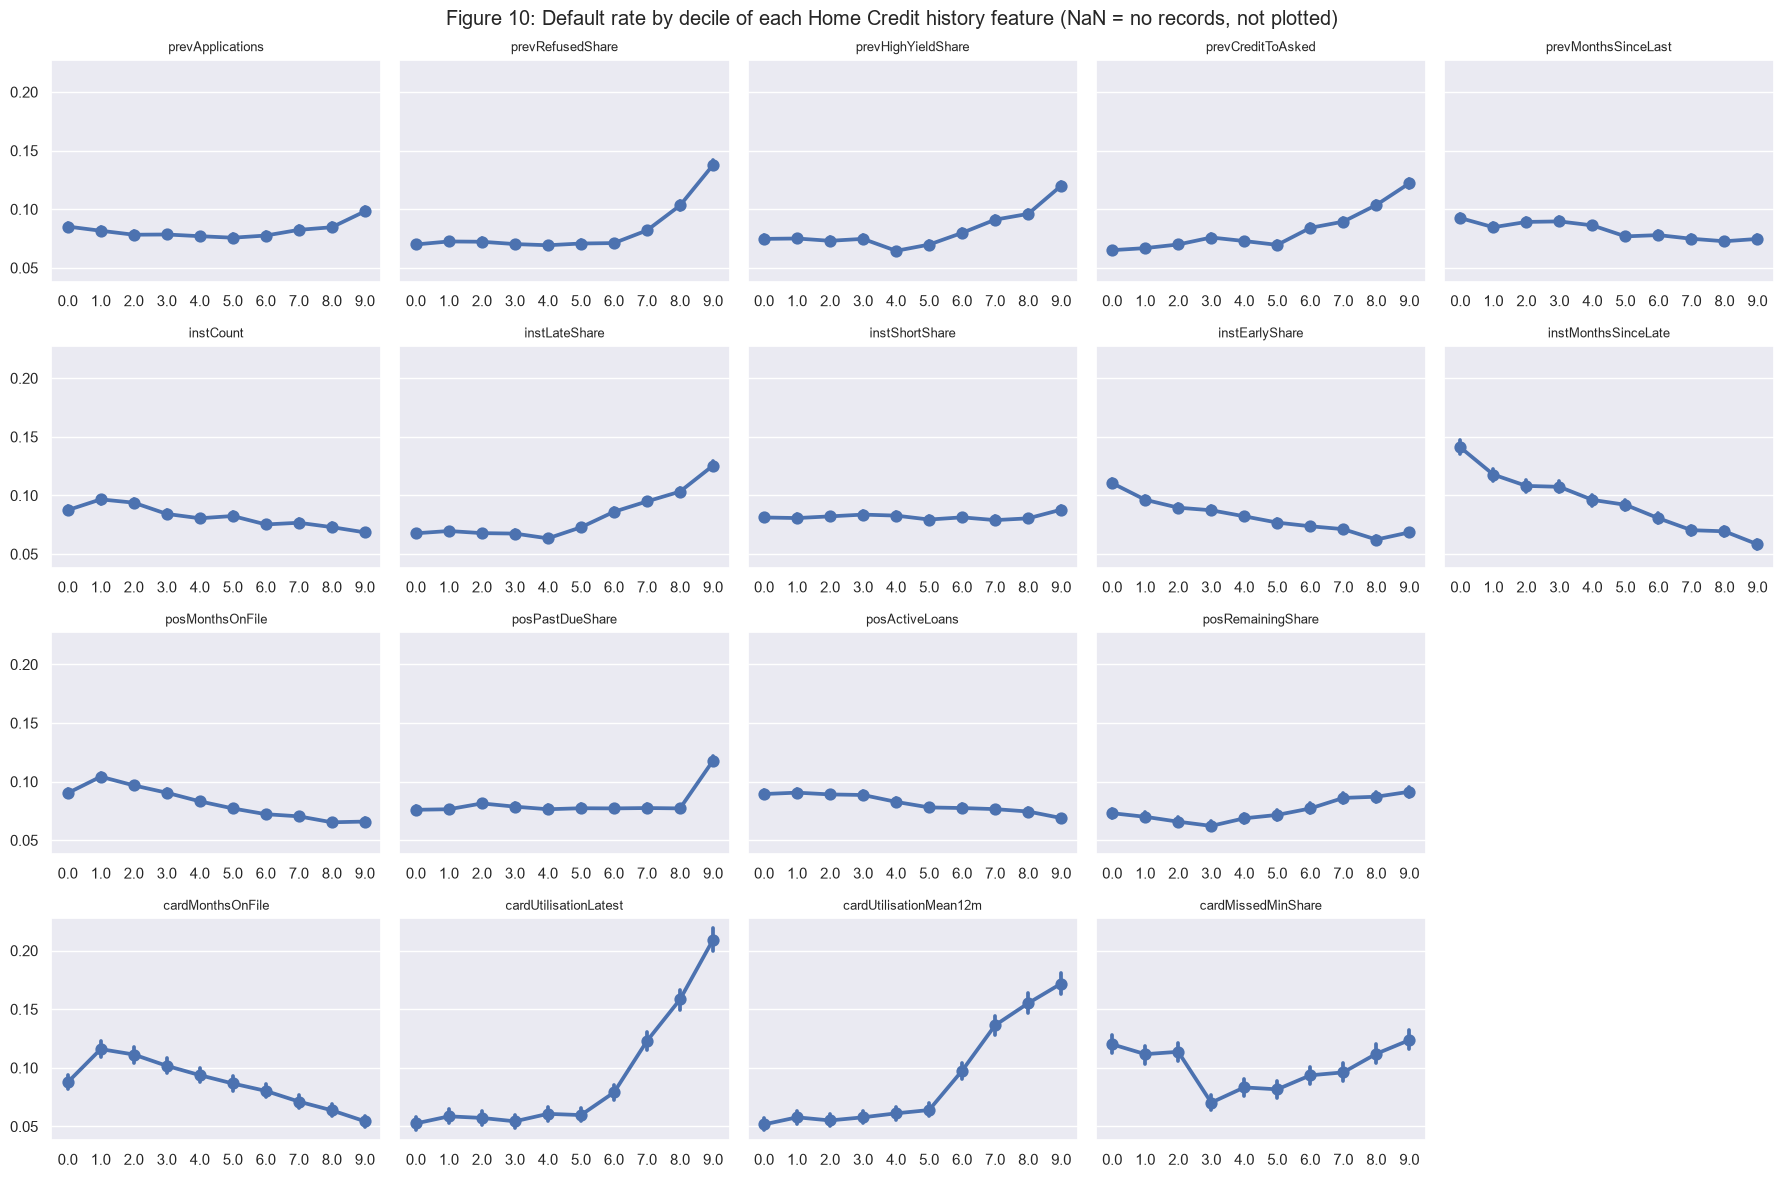

In [37]:
history_sources = ["prev", "inst", "pos", "card"]
plot_rows = [[c for c in df_hc.columns if c.startswith(source)] for source in history_sources]

n_cols = max(len(row_cols) for row_cols in plot_rows)
fig, axes = plt.subplots(len(plot_rows), n_cols, figsize=(18, 3 * len(plot_rows)), sharey=True)

for ax_row, row_cols in zip(axes, plot_rows):
    for ax, col in zip(ax_row, row_cols):
        s = df_hc[col]
        decile = pd.qcut(s.rank(method="first"), q=10, labels=False)  # rank so ties can't merge deciles.
        sns.pointplot(x=decile, y=target, color="C0", ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in ax_row[len(row_cols):]:
        ax.set_visible(False)

fig.suptitle("Figure 10: Default rate by decile of each Home Credit history feature (NaN = no records, not plotted)")
fig.tight_layout()
plt.show()

**H5 holds.** Default sits at about 7% for most applicants but climbs to 13.8% in the top decile of refused share, and from about 7.5% to 12% with the share of approvals priced as high risk. One surprise: applicants who were lent *more* than they asked for are riskier (6.5% → 12.2% across `prevCreditToAsked`). That's the same pattern as `creditToGoods`: a loan topped up, probably with fees or insurance, is a warning sign, not a vote of confidence.

**H6 holds, except for short payments.** The share of instalments paid late takes default from about 7% to 12.6%. A recent late instalment means 14% default, against 6% when it was long ago. Paying a week or more early cuts default from 11% to about 6–7%, the same story as the bureau early payoffs in H2. Paying short barely moves it (8.1% → 8.8%), and months past due on POS loans only matter in the top decile (11.8%).

**H7 holds: card utilisation is the steepest curve in the notebook.** Default is about 5–6% for the bottom half of latest utilisation and climbs to 21% in the top decile. Missing the minimum payment is less clear-cut (a U-shape), so utilisation carries the card signal.

## 8. Relationships between features

In [38]:
from sklearn.metrics import normalized_mutual_info_score


def bin_column(column, flags=()):
    """Deciles for continuous columns. NaN and flag values kept as their own bins. Categoricals as-is."""
    if column.name in categorical_cols or column.nunique() <= 12:
        return column
    is_flag = column.isin(flags)
    deciles = pd.qcut(column.where(~is_flag), q=10, labels=False, duplicates="drop") + 1  # 1-10, so no clash with a flag value of 0
    return deciles.fillna(column.where(is_flag))


df_binned = df_app[cols].apply(bin_column).apply(lambda column: column.factorize()[0])
df_mutual_info = df_binned.corr(method=normalized_mutual_info_score)
mask = np.triu(np.ones_like(df_mutual_info, dtype=bool), k=1)
mutual_info_pairs = df_mutual_info.where(mask).stack().dropna().sort_values(ascending=False)
mutual_info_pairs.head(15)

AMT_CREDIT                  AMT_GOODS_PRICE               0.635381
FLAG_OWN_CAR                OWN_CAR_AGE                   0.622213
AMT_REQ_CREDIT_BUREAU_MON   AMT_REQ_CREDIT_BUREAU_QRT     0.531740
                            AMT_REQ_CREDIT_BUREAU_YEAR    0.376695
AMT_REQ_CREDIT_BUREAU_QRT   AMT_REQ_CREDIT_BUREAU_YEAR    0.318565
AMT_CREDIT                  AMT_ANNUITY                   0.279612
NAME_INCOME_TYPE            YEARS_EMPLOYED                0.271138
AMT_ANNUITY                 AMT_GOODS_PRICE               0.266575
REGION_POPULATION_RELATIVE  REGION_RATING_CLIENT          0.235230
NAME_CONTRACT_TYPE          termMonths                    0.231617
YEARS_BIRTH                 YEARS_ID_PUBLISH              0.219208
EXT_SOURCE_3                AMT_REQ_CREDIT_BUREAU_MON     0.188824
AMT_CREDIT                  termMonths                    0.171232
EXT_SOURCE_3                AMT_REQ_CREDIT_BUREAU_QRT     0.165607
AMT_GOODS_PRICE             termMonths                    0.15

Mutual information is the KL divergence between the joint distribution and the product of the marginals. A high NMI means one column largely explains the other. So I will later drop one column of each high-NMI pair, so that logistic regression doesn't split one effect across two near-duplicates.

In [39]:
df_tl_all = df_tl_status.join(df_tl_new).join(df_hc)
df_tl_binned = df_tl_all.apply(bin_column, flags=[0]).apply(  # most bureau features are zero-inflated: 0 gets its own bin
    lambda column: column.factorize()[0])

df_binned_all = df_binned.join(df_tl_binned)
df_mutual_info_all = df_binned_all.corr(method=normalized_mutual_info_score)
mask = np.triu(np.ones_like(df_mutual_info_all, dtype=bool), k=1)
pairs = df_mutual_info_all.where(mask).stack().dropna()
has_tl = pairs.index.get_level_values(0).isin(df_tl_all.columns) | pairs.index.get_level_values(1).isin(df_tl_all.columns)
tl_mutual_info_pairs = pairs[has_tl].sort_values(ascending=False)
tl_mutual_info_pairs.head(30)

Other_monthsOnFile                Other_nAccountsMax                0.763953
Other_status_0_share              Other_nAccountsMax                0.686105
cardUtilisationLatest             cardUtilisationMean12m            0.659540
Credit card_monthsOnFile          Credit card_nAccountsMax          0.651272
Other_nActive                     Other_debtActive                  0.613577
Other_status_0_share              Other_monthsOnFile                0.590430
Credit card_status_0_share        Credit card_nAccountsMax          0.574951
Consumer credit_monthsOnFile      Consumer credit_nAccountsMax      0.570699
Credit card_nActive               Credit card_nCredits              0.534719
bureauEarlyPayoffs                monthsSinceBureauEarlyPayoff      0.530639
Consumer credit_status_0_share    Consumer credit_status_C_share    0.507589
instCount                         posMonthsOnFile                   0.496091
Consumer credit_status_0_share    Consumer credit_nAccountsMax      0.495365

# Model

## 1. Model Choice

I've decided to go ahead with **logistic regression**. It's the model I've had in mind throughout the EDA, and the strong dependence between features rules out methods such as naive Bayes.

Pros:
- It naturally produces probabilities for the target.
- It is interpretable, which matters for regulators and for explaining a decline to a customer.
- There is plenty of literature on it in credit scoring.

Cons:
- Struggles with non-linear features.
- Need to make sure it doesn't overfit (drop columns with high MI).
- Effects are additive on the log-odds, so interactions must be added by hand.

Alternatives like gradient boosting were considered, as they are very strong on tabular data, but I prefer to start with the simpler, more interpretable model. XGBoost is fitted as a challenger in section 4 to measure what that choice costs.

To handle non-linear features I use splines with 5 knots. This balances enough curvature against overfitting. I chose splines over polynomials because they extrapolate beyond the training range more reliably.

## 2. Data Preprocessing

### Linearity Check

Since we're using logistic regression, it's important to check the linearity of each column, as this decides how it enters the pipeline.
I bin each feature to roughly gauge its predictive power, then represent it as linear, log or flags only, and see how much of that signal each form "explains".
Binning sometimes loses information, hence values over 100%.
The threshold for falling back to splines is 85%.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss


def deviance(X):
    # deviance = 2 * n * log-loss; with no columns we just predict the average rate.
    if X.shape[1] == 0:
        p = np.full(len(target), target.mean())
    else:
        model = LogisticRegression(C=1e6, max_iter=2000)
        p = model.fit(X, target).predict_proba(X)[:, 1]
    return 2 * len(target) * log_loss(target, p)


def scale(x):
    # flagged rows are NaN, to be filled with the mean.
    return ((x - x.mean()) / x.std()).fillna(0)


def linearity(s, never_held=None):
    df_flags = pd.DataFrame(index=s.index)
    if s.isna().any():
        df_flags["missing"] = s.isna().astype(int)
    if never_held is not None:
        df_flags["never_held"] = never_held.astype(int)

    x = s.mask(df_flags.any(axis=1))
    if x.nunique() <= 12:
        bins = x
    else:
        bins = pd.qcut(x, 10, labels=False, duplicates="drop")

    d_average = deviance(pd.DataFrame(index=s.index))
    d_flags = deviance(df_flags)
    d_lin = deviance(df_flags.assign(x=scale(x)))
    d_log = deviance(df_flags.assign(x=scale(np.sign(x) * np.log1p(x.abs()))))
    d_bins = deviance(df_flags.join(pd.get_dummies(bins, prefix="bin", drop_first=True, dtype=int)))

    Pred_power = d_average - d_bins
    return {
        "Pred_power": Pred_power,
        "lin_%": 100 * (d_average - d_lin) / Pred_power,
        "log_%": 100 * (d_average - d_log) / Pred_power,
        "flags_%": 100 * (d_average - d_flags) / Pred_power,
    }


df_tl = df_tl_status.join(df_tl_new).join(df_hc)

rows = {}
for col in continuous_cols + ["REGION_RATING_CLIENT"]:
    rows[col] = linearity(df_app[col])

for col in df_tl.columns:
    account_type = next((t for t in account_types if col.startswith(t)), None)
    never_held = None if account_type is None else df_tl[f"{account_type}_nCredits"] == 0
    rows[col] = linearity(df_tl[col], never_held)


def choose_form(row):
    if row["lin_%"] >= 85:
        return "x"
    if row["log_%"] >= 85:
        return "log(x)"
    if row["flags_%"] >= 85:
        return "flags only"
    return "bins / spline"


df_linearity = pd.DataFrame(rows).T.round(0)
df_linearity["use"] = df_linearity.apply(choose_form, axis=1)
df_linearity.sort_values("Pred_power", ascending=False)

,Pred_power,lin_%,log_%,flags_%,use
EXT_SOURCE_3,7536.0,103.0,103.0,2.0,x
EXT_SOURCE_2,6979.0,103.0,103.0,0.0,x
EXT_SOURCE_1,3303.0,103.0,104.0,3.0,x
termMonths,2564.0,27.0,20.0,13.0,bins / spline
YEARS_EMPLOYED,2487.0,96.0,94.0,29.0,x
...,...,...,...,...,...
CNT_CHILDREN,39.0,280.0,305.0,0.0,x
Credit card_status_C_share,35.0,83.0,77.0,4.0,bins / spline
Credit card_status_X_share,23.0,10.0,12.0,6.0,bins / spline
Credit card_status_3-5_share,1.0,400.0,434.0,100.0,x


### Pipeline

- **Flags:** every column with missing values gets a 0/1 `_missing` indicator. The NaN itself is filled with the mean after scaling (and log, if used), so each feature becomes [x, 0] or [mean, 1]. This covers the `DAYS_EMPLOYED` placeholder too: `YEARS_EMPLOYED_missing` *is* the "not employed" flag.

In [41]:
def flag_attributes(app, min_count=30):
    df = app.drop(columns="TARGET", errors="ignore")
    df_indicators = pd.DataFrame(index=df.index)
    for col in df.columns:
        is_missing = df[col].isna()
        if is_missing.sum() >= min_count:
            df_indicators[f"{col}_missing"] = is_missing.astype(int)
    return df.join(df_indicators)


df_app_flagged = flag_attributes(df_app)

In [42]:
def flag_tradeline(tl):
    df = tl.copy()
    df_indicators = pd.DataFrame(index=df.index)

    for col in ["monthsSinceBureauEarlyPayoff", "monthsSinceLastMissedPayment"]:
        df_indicators[f"{col}_never"] = df[col].isna().astype(int)

    for account_type in account_types:
        never_held = df[f"{account_type}_nCredits"] == 0
        df_indicators[f"{account_type}_neverHeld"] = never_held.astype(int)
        account_cols = [c for c in df.columns if c.startswith(account_type)]
        df.loc[never_held, account_cols] = np.nan

    return df.join(df_indicators)


def drop_status_buckets(tl):
    return tl.drop(columns=[c for c in tl.columns if c.endswith("_status_0_share")])


df_tl_flagged = drop_status_buckets(flag_tradeline(df_tl_status.join(df_tl_new)))

I also drop each type's `status_0` share. The bucket shares sum to 1, so keeping all of them makes the columns collinear.

- **Home Credit history flags:** an applicant with no records in a table gets one `neverHeld` flag for that table, and its columns stay NaN. Gaps within a table (never late, nothing active, no card use in the last year) get their own `_missing` flag.

In [43]:
history_counts = {"prev": "prevApplications", "inst": "instCount", "pos": "posMonthsOnFile", "card": "cardMonthsOnFile"}


def flag_history(hc, min_count=30):
    df_indicators = pd.DataFrame(index=hc.index)
    for source, count_col in history_counts.items():
        never_held = hc[count_col].isna()
        df_indicators[f"{source}_neverHeld"] = never_held.astype(int)
        for col in [c for c in hc.columns if c.startswith(source) and c != count_col]:
            is_missing = hc[col].isna() & ~never_held
            if is_missing.sum() >= min_count:
                df_indicators[f"{col}_missing"] = is_missing.astype(int)
    return hc.join(df_indicators)


df_hc_flagged = flag_history(df_hc)

- **Encoding:** categorical data is one-hot encoded so the logistic regression doesn't read an order into the raw values. Levels with very few applications are grouped as "Other". The first listed level is the reference.

In [44]:
category_levels = {  # first level is the reference; unlisted levels become "Other"
    "NAME_INCOME_TYPE": ["Working", "Commercial associate", "Pensioner", "State servant"],
    "NAME_EDUCATION_TYPE": ["Secondary / secondary special", "Higher education", "Incomplete higher", "Lower secondary"],
    "NAME_FAMILY_STATUS": ["Married", "Single / not married", "Civil marriage", "Separated", "Widow"],
    "NAME_HOUSING_TYPE": ["House / apartment", "With parents", "Municipal apartment", "Rented apartment"],
}


def encode_attributes(app_flagged):
    df = app_flagged.copy()
    df["revolving"] = (df["NAME_CONTRACT_TYPE"] == "Revolving loans").astype(int)
    for col in ["FLAG_OWN_REALTY", "FLAG_OWN_CAR"]:
        df[col] = (df[col] == "Y").astype(int)

    dummies = []
    for col, levels in category_levels.items():
        values = pd.Categorical(df[col].where(df[col].isin(levels), "Other"), categories=[*levels, "Other"])
        dummies.append(pd.get_dummies(values, prefix=col, drop_first=True, dtype=int).set_axis(df.index))

    return df.drop(columns=["NAME_CONTRACT_TYPE", *category_levels]).join(dummies)


df_app_encoded = encode_attributes(df_app_flagged)

- **High mutual information:** for every pair with NMI > 0.5, drop the weaker column (by single-feature `Pred_power` in the linearity check). Otherwise near-duplicates split one effect between them and one gets a misleading sign.

In [45]:
all_pairs = pd.concat([mutual_info_pairs, tl_mutual_info_pairs])
power = df_linearity["Pred_power"]
model_cols = set(df_app_encoded.columns) | set(df_tl_flagged.columns) | set(df_hc_flagged.columns)
candidates = power.index.intersection(list(model_cols))  # skip categoricals (one-hot encoded) and status_0 shares (already dropped)
high_mi_drop = sorted({
    a if power[a] < power[b] else b
    for a, b in all_pairs[all_pairs > 0.5].index
    if a in candidates and b in candidates
})
all_pairs[all_pairs > 0.5].to_frame("NMI").assign(dropped=lambda d: [a if a in high_mi_drop else b if b in high_mi_drop else "(not a model column)" for a, b in d.index])

,,NMI,dropped
AMT_CREDIT,AMT_GOODS_PRICE,0.635381,AMT_CREDIT
FLAG_OWN_CAR,OWN_CAR_AGE,0.622213,(not a model column)
AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,0.531740,AMT_REQ_CREDIT_BUREAU_MON
Other_monthsOnFile,Other_nAccountsMax,0.763953,Other_nAccountsMax
Other_status_0_share,Other_nAccountsMax,0.686105,Other_nAccountsMax
cardUtilisationLatest,cardUtilisationMean12m,0.659540,cardUtilisationMean12m
Credit card_monthsOnFile,Credit card_nAccountsMax,0.651272,Credit card_nAccountsMax
Other_nActive,Other_debtActive,0.613577,Other_nActive
Other_status_0_share,Other_monthsOnFile,0.590430,(not a model column)
Credit card_status_0_share,Credit card_nAccountsMax,0.574951,Credit card_nAccountsMax


- **Duplicate flags:** 0/1 columns aren't in the linearity table, so the step above can't see them. A flag whose |correlation| with another 0/1 column exceeds 0.99 only splits that column's effect, e.g. `OWN_CAR_AGE_missing` is just "no car". Drop the flag, keep the substantive column. Correlation rather than raw agreement, because two rare flags agree on >99% of rows just by both being 0.

In [46]:
def duplicate_flags(df, threshold=0.99):
    is_flag = lambda c: c.endswith(("_missing", "_never", "_neverHeld"))
    names = [c for c in df.columns if df[c].dropna().isin([0, 1]).all()]
    corr = np.corrcoef(df[names].fillna(0).to_numpy(np.float32), rowvar=False)
    found = {}
    for i, j in zip(*np.triu_indices(len(names), k=1)):
        a, b = names[i], names[j]
        if abs(corr[i, j]) > threshold and (is_flag(a) or is_flag(b)) and a not in found and b not in found:
            drop, keep = (b, a) if is_flag(b) else (a, b)
            found[drop] = (keep, round(corr[i, j], 4))
    return pd.DataFrame(found, index=["duplicates", "correlation"]).T


df_duplicate_flags = duplicate_flags(df_app_encoded.join(df_tl_flagged).join(df_hc_flagged))
high_mi_drop += list(df_duplicate_flags.index)
df_duplicate_flags

,duplicates,correlation
OWN_CAR_AGE_missing,FLAG_OWN_CAR,-1.0
creditToGoods_missing,AMT_GOODS_PRICE_missing,1.0
DEF_30_CNT_SOCIAL_CIRCLE_missing,OBS_30_CNT_SOCIAL_CIRCLE_missing,1.0
AMT_REQ_CREDIT_BUREAU_QRT_missing,AMT_REQ_CREDIT_BUREAU_MON_missing,1.0
AMT_REQ_CREDIT_BUREAU_YEAR_missing,AMT_REQ_CREDIT_BUREAU_MON_missing,1.0
YEARS_EMPLOYED_missing,NAME_INCOME_TYPE_Pensioner,0.9996
termMonths_missing,revolving,0.9998


- **Linearity fixes and scaling:** the `use` column of the linearity table decides whether each column enters as x, log(x) or a spline.

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, SplineTransformer, StandardScaler


def signed_log(v):
    return np.sign(v) * np.log1p(np.abs(v))


def has_distinct_knots(x, n_knots=5):
    """Quantile knots collapse when most rows share one value (zero-inflated or mostly imputed columns)."""
    v = signed_log(x)
    knots = np.quantile(v.fillna(v.mean()), np.linspace(0, 1, n_knots))
    return bool(np.all(np.diff(knots) > 0))


X = df_app_encoded.join(df_tl_flagged).join(df_hc_flagged).drop(columns=high_mi_drop)

# form of each column comes straight from the linearity table; columns not in it (flags, encodings) fall through below
use = df_linearity["use"]
# ponytail: spline candidates whose knots collapse fall back to log(x); bins would keep more shape if it matters
spline_cols = [c for c in X.columns if use.get(c) == "bins / spline" and has_distinct_knots(X[c])]
log_cols = [c for c in X.columns if use.get(c) in ("log(x)", "bins / spline") and c not in spline_cols]

# everything else is either a 0/1 flag or left as x
binary_cols = []
linear_cols = []
for col in X.columns:
    if col in log_cols or col in spline_cols:
        continue
    if X[col].dropna().isin([0, 1]).all():
        binary_cols.append(col)
    else:
        linear_cols.append(col)

linear = make_pipeline(SimpleImputer(), StandardScaler())
log = make_pipeline(FunctionTransformer(signed_log), SimpleImputer(), StandardScaler())
spline = make_pipeline(FunctionTransformer(signed_log), SimpleImputer(),
                       SplineTransformer(n_knots=5, knots="quantile", extrapolation="linear"))

preprocess = ColumnTransformer([
    ("linear", linear, linear_cols),
    ("log", log, log_cols),
    ("spline", spline, spline_cols),
    ("binary", SimpleImputer(), binary_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('linear', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

- **Pipeline for test data:** `build_features` calls the same functions the training cells above use (`prepare_application`, `aggregate_monthly`, `flag_attributes`, ...), so the test set goes through identical steps.

1. **Units:** days → years, `DAYS_EMPLOYED` placeholder → NaN, affordability ratios.
2. **Bureau clean-up:** credit types grouped; records dated after application dropped (leakage).
3. **Monthly aggregate:** credits of the same type and month combined (worst status kept).
4. **Bureau features:** status shares, early payoffs, active debt, history length, recency and credit seeking.
5. **Home Credit history:** previous applications, collapsed instalments, POS / cash loans and cards; records after application dropped.
6. **Attribute flags:** NaN → mean plus an indicator. Test data gets the training indicator columns, not its own.
7. **Bureau and history flags:** "never" and never-held credit types or tables → NaN plus an indicator; `status_0` shares dropped.
8. **Encoding:** 0/1 for the Y/N flags and contract type, one-hot for the rest; high-MI columns dropped.
9. **`model`:** log / spline / scale / fill NaNs with the mean, then logistic regression. These steps are learned, so they are only fitted on training data.

Steps 1–8 only look at each applicant's own rows, so they can't leak between applicants.

In [48]:
def build_features(app, bureau, bb, prev, inst, pos, cc, columns=None):
    """Raw tables -> one row per applicant, built with the same steps as X."""
    app = prepare_application(app)
    ids = app.index

    bureau = label_credit_type(bureau[bureau["SK_ID_CURR"].isin(ids)])
    bureau, bb = drop_after_application(bureau, bb)
    agg = aggregate_monthly(bb, bureau)

    tl = build_status_shares(agg, ids)
    tl = tl.join(build_early_payoffs(bureau, ids))
    tl = tl.join(build_balance_features(bureau, ids))
    tl = tl.join(build_history_features(agg, bureau, ids))
    tl = drop_status_buckets(flag_tradeline(tl))

    prev, inst, pos, cc = (t[t["SK_ID_CURR"].isin(ids)] for t in (prev, inst, pos, cc))
    hc = build_history(*drop_history_after_application(prev, inst, pos, cc), ids)

    # test data keeps every flag, then reindex below matches it to the training columns
    min_count = 30 if columns is None else 1
    app = flag_attributes(app, min_count=min_count)
    hc = flag_history(hc, min_count=min_count)
    features = encode_attributes(app).join(tl).join(hc).drop(columns=high_mi_drop, errors="ignore")
    if columns is not None:
        features = features.reindex(columns=columns, fill_value=0)
    return features


model = make_pipeline(preprocess, LogisticRegression(max_iter=5000))

df_app_test = pd.read_csv("data/application_test.csv", usecols=app_cols)
X_test = build_features(df_app_test, df_bureau, df_bb, df_prev, df_inst, df_pos, df_cc, columns=X.columns)
X_test

,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,OWN_CAR_AGE,REGION_RATING_CLIENT,EXT_SOURCE_1,...,prevHighYieldShare_missing,prevCreditToAsked_missing,inst_neverHeld,instMonthsSinceLate_missing,pos_neverHeld,posRemainingShare_missing,card_neverHeld,cardUtilisationLatest_missing,cardUtilisationMean12m_missing,cardMissedMinShare_missing
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,0,1,0,135000.0,20560.5,450000.0,0.018850,NaN,2,0.752614,...,0,0,0,0,0,1,1,0,0,0
100005,0,1,0,99000.0,17370.0,180000.0,0.035792,NaN,2,0.564990,...,0,0,0,0,0,1,1,0,0,0
100013,1,1,0,202500.0,69777.0,630000.0,0.019101,5.0,2,NaN,...,0,0,0,0,0,1,0,0,0,0
100028,0,1,2,315000.0,49018.5,1575000.0,0.026392,NaN,2,0.525734,...,0,0,0,0,0,1,0,0,0,0
100038,1,0,1,180000.0,32067.0,625500.0,0.010032,16.0,2,0.202145,...,0,0,0,1,0,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
456221,0,1,0,121500.0,17473.5,270000.0,0.002042,NaN,3,NaN,...,0,0,0,1,0,1,1,0,0,0
456222,0,0,2,157500.0,31909.5,495000.0,0.035792,NaN,2,NaN,...,0,0,0,0,0,0,1,0,0,0
456223,1,1,1,202500.0,33205.5,315000.0,0.026392,4.0,2,0.733503,...,0,0,0,1,0,0,1,0,0,0


## 3. Model Training and Performance

In [49]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(5, shuffle=True, random_state=0)

search = GridSearchCV(
    model,
    {"logisticregression__C": [0.01, 0.1, 1, 10]},
    cv=cv,
    scoring=["neg_log_loss", "roc_auc", "average_precision"],
    refit="neg_log_loss",     # pick C by log-loss; the others are reported only.
    return_train_score=True,  # also score the training folds, to compare with the held-out fold.
    n_jobs=4,                 # ponytail: 4 parallel fits fit in 16 GB; raise with more RAM
)
search.fit(X, target)
pd.DataFrame(search.cv_results_).filter(regex="param_|mean_(train|test)_").round(4)

,param_logisticregression__C,mean_test_neg_log_loss,mean_train_neg_log_loss,mean_test_roc_auc,mean_train_roc_auc,mean_test_average_precision,mean_train_average_precision
0,0.01,-0.2437,-0.2433,0.7671,0.7684,0.2525,0.2540
1,0.10,-0.2436,-0.2432,0.7674,0.7687,0.2527,0.2544
2,1.00,-0.2436,-0.2432,0.7673,0.7687,0.2527,0.2545
3,10.00,-0.2436,-0.2432,0.7673,0.7687,0.2527,0.2545


- **Performance plots:** all scored on out-of-fold predictions from the tuned model, so every applicant is scored by a model that never saw them. The table compares against always predicting the average default rate.

In [50]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import cross_val_predict

# Out-of-fold predictions from the tuned model. Each applicant is scored by a model that never saw them.
best_model = search.best_estimator_
oof_pred = cross_val_predict(best_model, X, target, cv=cv, method="predict_proba", n_jobs=4)[:, 1]
baseline_pred = np.full(len(target), target.mean())

pd.DataFrame({
    "tuned model (out of fold)": [log_loss(target, oof_pred), roc_auc_score(target, oof_pred), average_precision_score(target, oof_pred)],
    "always predict the average": [log_loss(target, baseline_pred), 0.5, target.mean()],
}, index=["log-loss", "ROC AUC", "average precision"]).round(4)

,tuned model (out of fold),always predict the average
log-loss,0.2436,0.2805
ROC AUC,0.7673,0.5000
average precision,0.2521,0.0807


- **Ranking:** ROC and precision-recall curves. The grey lines are what random ranking would score.

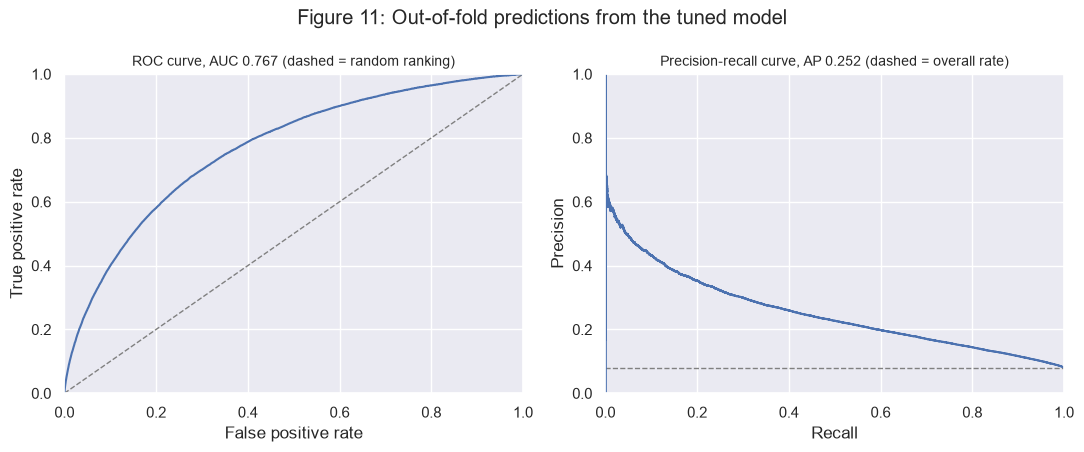

In [51]:
fpr, tpr, _ = roc_curve(target, oof_pred)
precision, recall, _ = precision_recall_curve(target, oof_pred)

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.6))

ax_roc.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
ax_roc.plot(fpr, tpr, color="C0")
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
ax_roc.set_title(f"ROC curve, AUC {roc_auc_score(target, oof_pred):.3f} (dashed = random ranking)", fontsize=10)

ax_pr.axhline(target.mean(), color="grey", ls="--", lw=1)
ax_pr.plot(recall, precision, color="C0")
ax_pr.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax_pr.set_title(f"Precision-recall curve, AP {average_precision_score(target, oof_pred):.3f} (dashed = overall rate)", fontsize=10)

fig.suptitle("Figure 11: Out-of-fold predictions from the tuned model")
fig.tight_layout()
plt.show()

The ROC curve sits well above the diagonal (AUC 0.767). Precision starts around 60% for the very highest scores and falls quickly; at 20% recall, about 36% of flagged applicants default, roughly 4.5× the 8.1% base rate. Individual defaults are hard to pick out, but the ranking is far from random.

- **Calibration:** applicants grouped into deciles of predicted probability; points on the diagonal mean the predicted probabilities match the observed default rate.

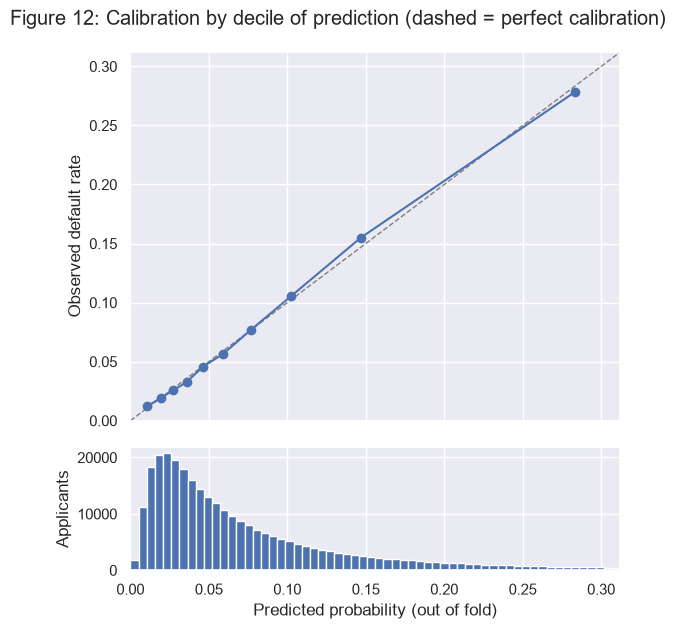

,predicted,observed
0,1.1%,1.2%
1,1.9%,1.9%
2,2.7%,2.6%
3,3.6%,3.3%
4,4.6%,4.6%
5,5.9%,5.7%
6,7.7%,7.7%
7,10.2%,10.5%
8,14.7%,15.5%
9,28.4%,27.9%


In [52]:
observed, predicted = calibration_curve(target, oof_pred, n_bins=10, strategy="quantile")

fig, (ax, ax_hist) = plt.subplots(2, 1, figsize=(6, 6.4), sharex=True, height_ratios=[3, 1])
top = max(observed.max(), predicted.max()) * 1.1

ax.plot([0, top], [0, top], color="grey", ls="--", lw=1)
ax.plot(predicted, observed, color="C0", marker="o")
ax.set(ylabel="Observed default rate", xlim=(0, top), ylim=(0, top))

ax_hist.hist(oof_pred, bins=60, range=(0, top), color="C0")
ax_hist.set(xlabel="Predicted probability (out of fold)", ylabel="Applicants")

fig.suptitle("Figure 12: Calibration by decile of prediction (dashed = perfect calibration)")
fig.tight_layout()
plt.show()

pd.DataFrame({"predicted": predicted, "observed": observed}).map("{:.1%}".format)

Calibration is good: 8 of the 10 deciles are within 0.3 points of the observed rate, and the worst is 14.7% predicted vs 15.5% observed. So the probabilities can be used directly, e.g. in an expected-loss estimate. Predictions range from 1.1% in the lowest decile to 28.4% in the highest, a 26× spread, with the top decile at about 3.5× the 8.07% base rate.

- **What the model learned:** coefficients for the linear, log and 0/1 columns, then the fitted curve for each spline column.

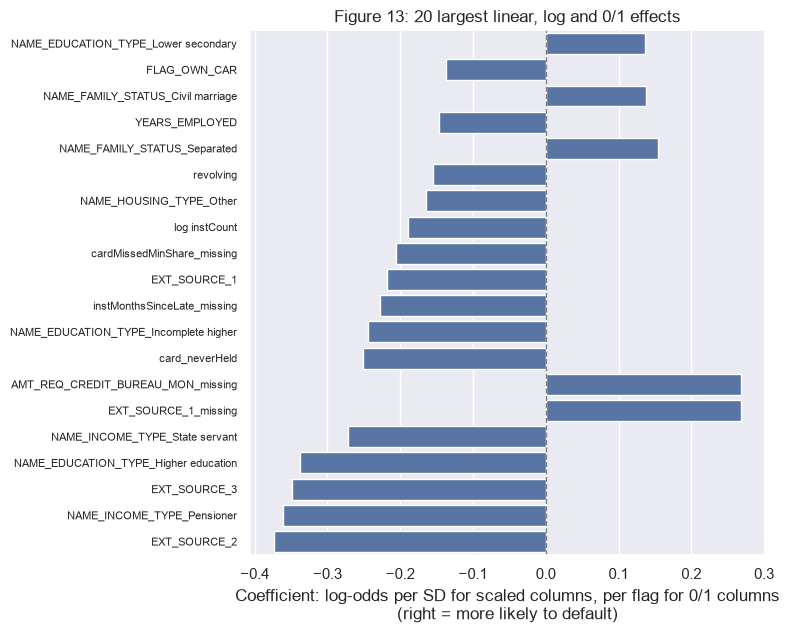

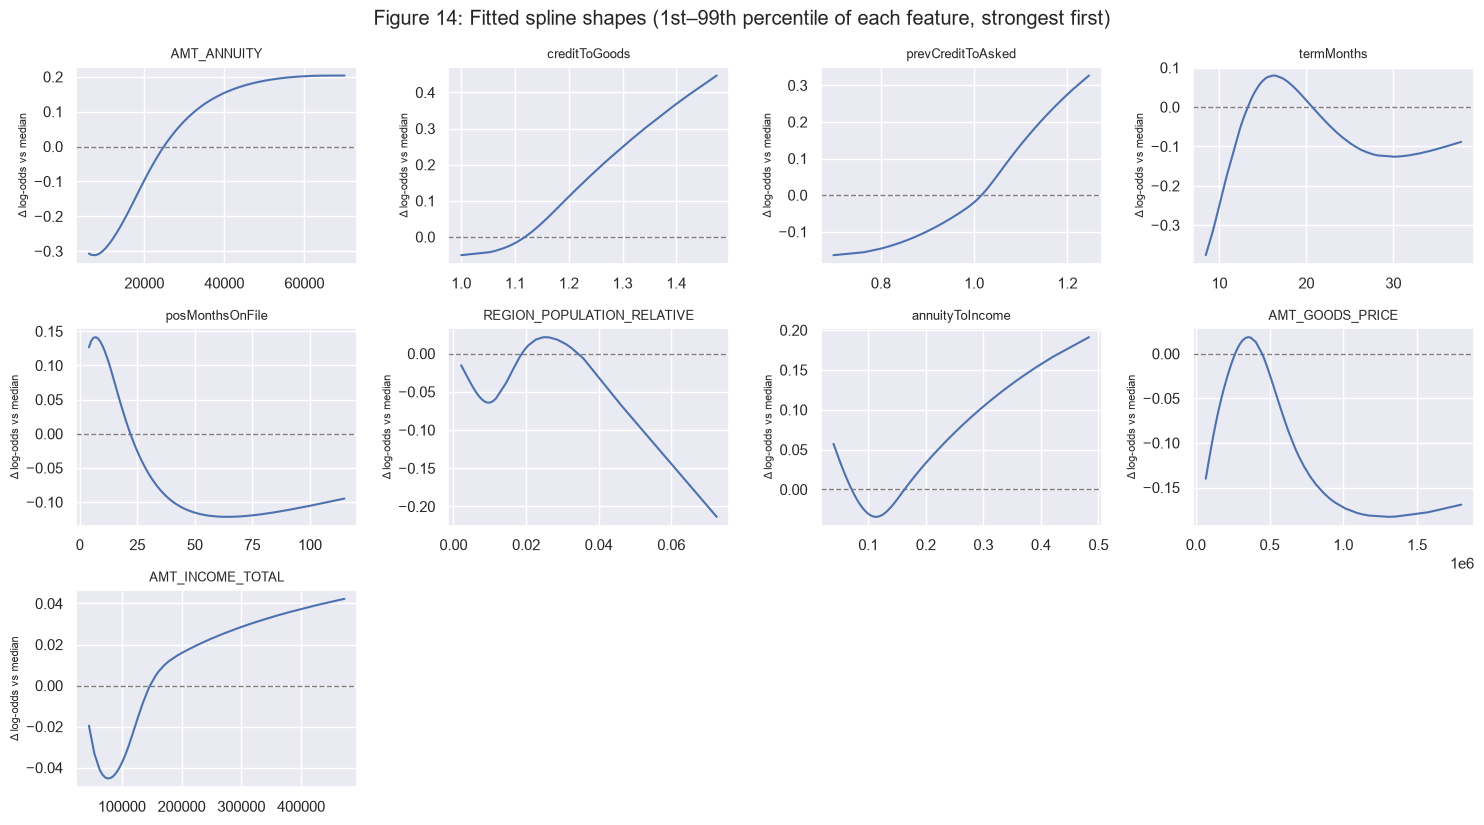

In [53]:
pre, logreg = best_model[0], best_model[-1]
coef = logreg.coef_[0]

# Linear, log and 0/1 columns: one coefficient each.
names = {}
for group, group_cols in [("linear", linear_cols), ("log", log_cols), ("binary", binary_cols)]:
    idx = pre.output_indices_[group]
    names.update(zip(range(idx.start, idx.stop), [f"log {c}" if group == "log" else c for c in group_cols]))
coefs = pd.Series({name: coef[i] for i, name in names.items()})
top = coefs.reindex(coefs.abs().sort_values().index)[-20:]

# Spline columns: the fitted curve, as the change in log-odds relative to the feature's median.
idx = pre.output_indices_["spline"]
n_basis = (idx.stop - idx.start) // len(spline_cols)
spline_pipe, spline_coef = pre.named_transformers_["spline"], coef[idx]
curves = {}
for k, col in enumerate(spline_cols):
    grid_values = np.quantile(X[col].dropna(), np.linspace(0.01, 0.99, 99))
    frame = pd.DataFrame({c: X[c].median() for c in spline_cols}, index=range(len(grid_values) + 1))
    frame[col] = np.append(grid_values, X[col].median())
    effect = spline_pipe.transform(frame)[:, k * n_basis:(k + 1) * n_basis] @ spline_coef[k * n_basis:(k + 1) * n_basis]
    curves[col] = pd.Series(effect[:-1] - effect[-1], index=grid_values)
order = sorted(curves, key=lambda c: curves[c].max() - curves[c].min(), reverse=True)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.barplot(x=top.values, y=top.index, color="C0", ax=ax)
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_xlabel("Coefficient: log-odds per SD for scaled columns, per flag for 0/1 columns\n"
              "(right = more likely to default)")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Figure 13: 20 largest linear, log and 0/1 effects")
fig.tight_layout()
plt.show()

fig, axes = grid(len(order), height=2.8)
for ax, col in zip(axes, order):
    ax.axhline(0, color="grey", ls="--", lw=1)
    ax.plot(curves[col].index, curves[col].values, color="C0")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("Δ log-odds vs median", fontsize=8)
fig.suptitle("Figure 14: Fitted spline shapes (1st–99th percentile of each feature, strongest first)")
fig.tight_layout()
plt.show()

- **Train vs test:** if the test applicants looked different to the model, their predicted probabilities would shift. There are no dates to check drift directly, so this is the only check available.

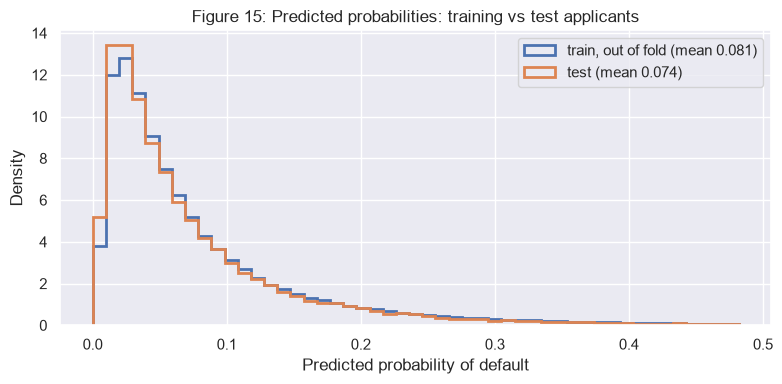

In [54]:
test_pred = best_model.predict_proba(X_test)[:, 1]
bins = np.linspace(0, np.quantile(np.append(oof_pred, test_pred), 0.995), 50)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(oof_pred, bins=bins, density=True, histtype="step", color="C0", lw=2,
        label=f"train, out of fold (mean {oof_pred.mean():.3f})")
ax.hist(test_pred, bins=bins, density=True, histtype="step", color="C1", lw=2,
        label=f"test (mean {test_pred.mean():.3f})")
ax.set(xlabel="Predicted probability of default", ylabel="Density")
ax.set_title("Figure 15: Predicted probabilities: training vs test applicants")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## 4. Challenger: XGBoost

The logistic regression only learns the shapes I gave it, and no interactions. As a check, I fit gradient-boosted trees on the same features and folds. If XGBoost clearly beats it on log-loss, there is structure (mostly interactions) the logistic regression is missing.

- **Same `X`:** trees don't need logs, splines or scaling, and handle NaN natively, so the `_missing` flags are redundant but harmless.
- **Number of trees:** early stopping on log-loss over the same 5 folds. The other settings are common choices for data this size, not tuned.
- **Hardware:** trained on the GPU (RTX 2080 Super).

In [55]:
import warnings

import xgboost as xgb
from sklearn.metrics import brier_score_loss

warnings.filterwarnings("ignore", message=".*mismatched devices")  # the model is on the GPU, the data to predict on the CPU; harmless

xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "device": "cuda",
    "tree_method": "hist",
    "learning_rate": 0.03,
    "max_depth": 6,
    "min_child_weight": 10,
    "subsample": 0.8,
    "colsample_bytree": 0.5,
}
# ponytail: trees picked on the same folds they're scored on, so slightly optimistic; a nested split if it matters
xgb_cv = xgb.cv(xgb_params, xgb.DMatrix(X, label=target), num_boost_round=5000,
                folds=list(cv.split(X, target)), early_stopping_rounds=100, seed=0)
n_trees = len(xgb_cv)

xgb_model = xgb.XGBClassifier(**xgb_params, n_estimators=n_trees, random_state=0)
xgb_oof = cross_val_predict(xgb_model, X, target, cv=cv, method="predict_proba")[:, 1]


def scores(p):
    return [log_loss(target, p), roc_auc_score(target, p), average_precision_score(target, p), brier_score_loss(target, p)]


pd.DataFrame({
    "logistic regression": scores(oof_pred),
    f"XGBoost ({n_trees} trees)": scores(xgb_oof),
    "always predict the average": scores(baseline_pred),
}, index=["log-loss", "ROC AUC", "average precision", "Brier score"]).round(4)

,logistic regression,XGBoost (976 trees),always predict the average
log-loss,0.2436,0.2383,0.2805
ROC AUC,0.7673,0.7829,0.5000
average precision,0.2521,0.2762,0.0807
Brier score,0.0673,0.0662,0.0742


In [56]:
# Spread across the 5 folds: score each fold's held-out applicants separately.
# Same seeded StratifiedKFold as cross_val_predict, so these are the same folds.
folds = list(cv.split(X, target))
y = np.asarray(target)


def fold_scores(p):
    rows = [[roc_auc_score(y[test], p[test]), brier_score_loss(y[test], p[test])] for _, test in folds]
    return pd.DataFrame(rows, columns=["ROC AUC", "Brier score"]).agg(["mean", "std"])


pd.concat({"logistic regression": fold_scores(oof_pred), "XGBoost": fold_scores(xgb_oof)}, axis=1).round(4)

logistic regression             XGBoost            
                 ROC AUC Brier score ROC AUC Brier score
mean              0.7674      0.0673  0.7829      0.0662
std               0.0043      0.0003  0.0041      0.0003

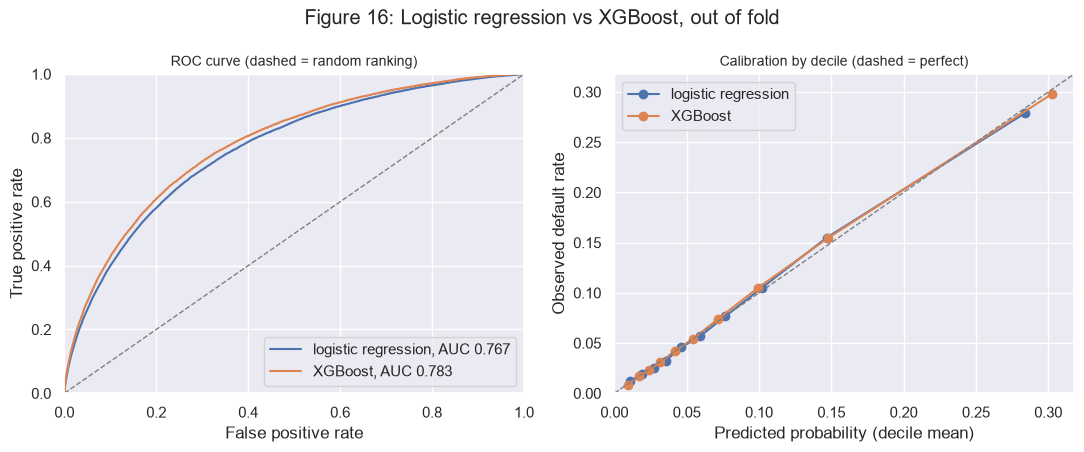

In [57]:
fig, (ax_roc, ax_cal) = plt.subplots(1, 2, figsize=(11, 4.6))

ax_roc.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
cal_top = 0
for name, p, color in [("logistic regression", oof_pred, "C0"), ("XGBoost", xgb_oof, "C1")]:
    fpr, tpr, _ = roc_curve(target, p)
    ax_roc.plot(fpr, tpr, color=color, label=f"{name}, AUC {roc_auc_score(target, p):.3f}")
    observed, predicted = calibration_curve(target, p, n_bins=10, strategy="quantile")
    ax_cal.plot(predicted, observed, color=color, marker="o", label=name)
    cal_top = max(cal_top, observed.max(), predicted.max())
cal_top *= 1.05

ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
ax_roc.set_title("ROC curve (dashed = random ranking)", fontsize=10)
ax_roc.legend(loc="lower right")
ax_cal.plot([0, cal_top], [0, cal_top], color="grey", ls="--", lw=1)
ax_cal.set(xlabel="Predicted probability (decile mean)", ylabel="Observed default rate", xlim=(0, cal_top), ylim=(0, cal_top))
ax_cal.set_title("Calibration by decile (dashed = perfect)", fontsize=10)
ax_cal.legend(loc="upper left")

fig.suptitle("Figure 16: Logistic regression vs XGBoost, out of fold")
fig.tight_layout()
plt.show()

- **What XGBoost relies on:** total gain per feature from a fit on all training applicants. Compare with Figures 13 and 14.

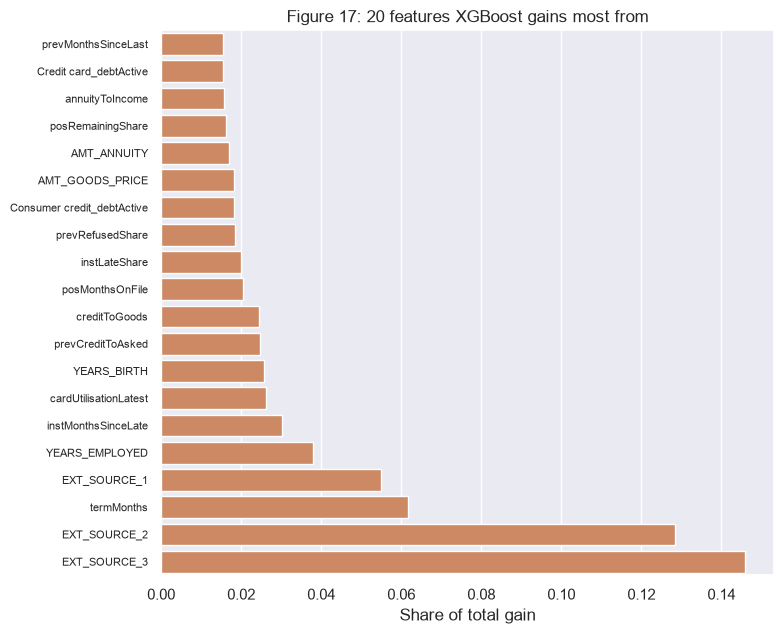

In [58]:
xgb_model.fit(X, target)
gain = pd.Series(xgb_model.get_booster().get_score(importance_type="total_gain"))
gain = (gain / gain.sum()).sort_values()[-20:]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.barplot(x=gain.values, y=gain.index, color="C1", ax=ax)
ax.set_xlabel("Share of total gain")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Figure 17: 20 features XGBoost gains most from")
fig.tight_layout()
plt.show()

XGBoost wins on every metric, but not by much: log-loss 0.2383 vs 0.2436 (2% lower), AUC 0.783 vs 0.767 and average precision 0.276 vs 0.252. Both are well calibrated (Figure 16); XGBoost spreads its predictions a little wider, with a top decile at about 30% against 28%.

Its top features are the same ones the logistic regression relies on: `EXT_SOURCE_3` and `_2` take over a quarter of the gain, followed by `EXT_SOURCE_1`, `YEARS_EMPLOYED`, age, `creditToGoods` and the history features (`instMonthsSinceLate`, `cardUtilisationLatest`, `prevCreditToAsked`). The one that stands out is `termMonths` in third place, much higher than its role in the logistic regression. Since it is `AMT_CREDIT / AMT_ANNUITY`, trees can combine it with the loan amounts, which points to interactions the logistic regression can't see.

So the gap is real, but it comes from interactions and finer shapes, not from features the logistic regression ignored. For a lender, 0.016 AUC has to be weighed against coefficients that can be explained to a regulator and to a declined customer.

# Summary

## Hypotheses

- **H1 (affordability net of risk): weakly supported.** The raw burden effect is small (Figure 4, "All" row), but within the riskiest score decile default rises from 16.9% to 20.3% with burden. The fitted `annuityToIncome` curve (Figure 14) climbs about 0.2 log-odds between a 12% and a 48% burden.
- **H2 (credit seeking vs paying down): supported.** Credits opened in the last 12 months, recent missed payments and card debt all raise default; early payoffs lower it (Figure 9).
- **H3 (homeowners and pensioners): half right.** Pensioners are among the largest effects in the model (−0.36 log-odds, Figure 13; 5.4% vs 9.6% raw), but owning property makes almost no difference (Figure 5).
- **H4 (term): wrong.** Default peaks at mid-length terms and is lowest for the longest loans, within score bands too (Figure 3). The fitted spline (Figure 14) peaks at about 16 months. The likely reason is selection: long terms go to applicants the lender already trusts.
- **H5 (Home Credit's own judgement): supported.** A high refused share or high-price approvals both raise default, to 13.8% and 12% in their top deciles (Figure 10).
- **H6 (repayment behaviour): supported, except short payments.** Late instalments raise default, paying early lowers it, and recency matters (Figure 10). Never having been late on a Home Credit instalment is worth about −0.23 log-odds (Figure 13).
- **H7 (stretched on cards): strongly supported.** The top decile of card utilisation defaults at 21% (Figure 10).

## Further Analysis

**Model performance**
- Out of fold, the tuned model beats always predicting the average on every metric: log-loss 0.2436 vs 0.2805, ROC AUC 0.767 vs 0.5, and average precision 0.252 vs 0.081.
- Adding the four Home Credit history tables, with the model unchanged, raised AUC from 0.751 to 0.767 and cut log-loss from 0.2484 to 0.2436. All of the gain came from the features.
- Regularisation hardly matters: held-out log-loss is flat across C = 0.01–10, and train and held-out scores are almost identical (AUC 0.769 vs 0.767). With 307k applicants the model is not overfitting; the limit is the features.
- Calibration is good (Figure 12), so the probabilities can feed straight into an expected-loss estimate.
- An XGBoost challenger on the same features and folds does better (AUC 0.783, log-loss 0.2383) and is equally well calibrated (Figure 16). Its top features match the logistic regression's (Figure 17), so the gap is interactions and finer shapes, not missed features.
- The test applicants' predictions have the same shape as the training applicants', but a slightly lower mean (0.074 vs 0.081, Figure 15): the test set looks a little safer to the model. Kaggle's score on the hidden labels is the real check.

**Findings outside the hypotheses**
- **External scores dominate:** the three `EXT_SOURCE` scores top the single-feature ranking in the linearity table, and `EXT_SOURCE_2` and `_3` are among the largest coefficients (Figure 13).
- **Missing data is signal:** applicants without `EXT_SOURCE_1`, or without bureau enquiry data, are riskier (about +0.27 log-odds each). Applicants who never held a Home Credit card, or were never late on a Home Credit instalment, are safer (about −0.25 and −0.23, Figure 13).
- **Being lent more than needed:** `creditToGoods` and `prevCreditToAsked` both raise default steadily once above 1 (Figure 14). Topped-up loans look like a warning sign in both the current and previous applications.
- **Length of relationship:** a longer Home Credit history lowers risk: `log instCount` is about −0.19 (Figure 13), and the `posMonthsOnFile` spline falls from +0.14 for the newest customers to about −0.12 (Figure 14).
- **Duplicate flags:** in an earlier run without the duplicate-flag check, `NAME_INCOME_TYPE_Pensioner` and `YEARS_EMPLOYED_missing` (99.96% correlated) split one effect between them, and the car effect showed up as −0.49 on `FLAG_OWN_CAR` and −0.32 on its complement `OWN_CAR_AGE_missing`, when the net effect was −0.17. The check doesn't change predictions, but without it the coefficients would mislead.

# Next Steps

- **Richer history features:** I kept each Home Credit table to a handful of summaries. Trends (is lateness getting worse?) and the size of late payments, not just their count, are the obvious next additions.
- **Interactions:** XGBoost beats the logistic regression by 0.016 AUC on the same features (section 4). Its strongest split pairs, starting with `termMonths` and the loan amounts, are the candidates to add to the logistic regression by hand to close that gap while keeping it interpretable.
- **Fairness check:** gender was excluded as a feature, but default rates and calibration can still be compared by gender to check the model isn't using proxies for it.
- **Better linearity check:** I kept this brief, but it's important enough that reworking it could improve performance by classifying columns correctly.

# Submission

Kaggle scores submissions by ROC AUC on the hidden test labels. `submission.csv` is the logistic regression; `submission_xgboost.csv` is the challenger:

```
kaggle competitions submit -c home-credit-default-risk -f submission.csv -m "logistic regression + splines"
kaggle competitions submit -c home-credit-default-risk -f submission_xgboost.csv -m "XGBoost challenger"
```

In [59]:
submission = pd.DataFrame({"SK_ID_CURR": X_test.index, "TARGET": test_pred})
submission.to_csv("submission.csv", index=False)

# XGBoost challenger, submitted separately to compare Kaggle scores
submission.assign(TARGET=xgb_model.predict_proba(X_test)[:, 1]).to_csv("submission_xgboost.csv", index=False)